# Flood Segmentation — Complete, Consistent Re-training (Deliverable 3)

This single Colab notebook covers **dataset extraction → corrected masks → one common split → non-IID clients → all models → checkpoints → every validation/test metric → graphs → predictions and error maps → computational measurements → exports**. Press **Runtime → Run all** with a GPU attached.

**Based on your two original notebooks:** `D3_Code_01.ipynb` (U-Net) and `D3-Code-02.ipynb` (ResNet-50). The primary goal is a genuinely *new* matched comparison; **do not combine the new numbers with your previous paper tables**. All models now share the same image/mask corrections, image identities in train/validation/test, client membership, labeled/unlabeled selections, rounds, batch budget, segmentation threshold, and evaluation protocol. ResNet uses ImageNet standardization (required for pretrained encoder); U-Net uses [0,1] RGB inputs. Architecture-specific image standardization is explicitly retained and documented.

Runs by default (all from scratch, separate checkpoints):

1. ResNet centralized, **100%** labels
2. ResNet FedAvg, **100%** labels
3. ResNet FedAvg, **20%** labels only
4. ResNet FedAvg + student–teacher, **20%** labels
5. ResNet FedProx, **20%** labels only (**additional ablation**)
6. ResNet FedProx + student–teacher, **20%** labels (**proposed**)
7. U-Net FedProx, **100%** labels
8. U-Net FedProx, **20%** labels only (**additional ablation**)
9. U-Net FedProx + student–teacher, **20%** labels

**Important experimental constraints:** Supervised 100%-label references are *upper-reference configurations*, not label-budget matched baselines. The reference Islam et al. paper uses a different evaluation protocol; published numbers are retained for descriptive context only. Runs use one model seed by default; adding seeds yields multiple runs and enables mean/std. A long Colab run can disconnect: the last completed epoch/round is saved to Drive; rerunning **Run all** resumes automatically. A crash *inside* a round restarts that round. No actual final scores are assumed before execution.

Before Run all, upload `flood_area.zip` to `/content/drive/MyDrive/DLP_Project/flood_area.zip` (same path as the original notebooks). Use a Colab GPU runtime. Checkpoints and results are saved under a **new** folder so previous experiments are untouched.

## Block 1 — Imports, Drive, hardware and reproducibility

In [1]:
from pathlib import Path
import os, gc, json, time, zipfile, random, hashlib, math, shutil, warnings
from contextlib import nullcontext
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.transforms import ColorJitter
from torch.utils.data import Dataset, DataLoader, Subset
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running inside Colab; Google Drive mounting skipped.')

ZIP_PATH = Path('/content/drive/MyDrive/DLP_Project/flood_area.zip')
PROJECT = ZIP_PATH.parent / 'D3_CONTROLLED_RERUN_2026'
DATA_ROOT_LOCAL = Path('/content/d3_common_flood_dataset')
CACHE_ROOT = Path('/content/d3_common_flood_cache')
PROJECT.mkdir(parents=True, exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.is_file(), f'Dataset ZIP missing: {ZIP_PATH}'
assert torch.cuda.is_available(), 'Please enable a GPU in Colab: Runtime > Change runtime type > GPU.'
DEVICE = torch.device('cuda')
print('PyTorch:', torch.__version__, '| Torchvision:', torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0))
print('GPU total GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

SEED_SPLIT = 42
MODEL_SEEDS = [42]  # change to [42, 123, 456] for 3 independent training repetitions
IMAGE_SIZE = (512, 512)
CLIENT_SIZES = [108, 51, 58]
CLIENT_STEPS = [14, 7, 8]
LABELED_COUNTS = [22, 10, 12]
BATCH_SIZE = 8
MICRO_BATCH = 2  # per-device minibatch; gradient accumulation yields effective batch size 8
VAL_BATCH = 2
LR = 0.001
BETAS = (0.9, 0.999)
CENTRAL_EPOCHS = 60
FED_ROUNDS = 60
MU = 0.01
PSEUDO_CONFIDENCE = 0.95
MAX_EMA_DECAY = 0.99
PRED_THRESHOLD = 0.50
AMP = True
NUM_WORKERS = 0  # reproducible across runtime restarts; no background worker state
ALGORITHM_VERSION = 'common-dataset-shared-steps-ssl-v2'
assert BATCH_SIZE % MICRO_BATCH == 0
assert sum(CLIENT_SIZES) == 217 and sum(LABELED_COUNTS) == 44

# Determinism: may be slower than nondeterministic CuDNN.
# CUBLAS_WORKSPACE_CONFIG is set before operations; a fresh runtime is recommended.
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception:
    pass

def seed_everything(seed):
    random.seed(int(seed)); np.random.seed(int(seed) % (2**32 - 1))
    torch.manual_seed(int(seed)); torch.cuda.manual_seed_all(int(seed))

seed_everything(SEED_SPLIT)
print('All configuration values initialized. Output:', PROJECT)

Mounted at /content/drive
PyTorch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130
GPU: Tesla T4
GPU total GiB: 14.56
All configuration values initialized. Output: /content/drive/MyDrive/DLP_Project/D3_CONTROLLED_RERUN_2026


## Block 2 — Read original ZIP, validate source files, and apply *the same* mask-pair corrections to both architectures

In [2]:
# Use the original metadata.csv order. We DO NOT change image pixels or silently drop samples.
with zipfile.ZipFile(ZIP_PATH) as z:
    names = [x.filename for x in z.infolist() if not x.is_dir() and '__MACOSX' not in x.filename]
    meta_matches = [n for n in names if Path(n).name.lower() == 'metadata.csv']
    assert len(meta_matches) == 1, f'Expected one metadata.csv, got: {meta_matches}'
    metadata_member = meta_matches[0]
    prefix = str(Path(metadata_member).parent)
    if prefix == '.': prefix = ''
    if not (DATA_ROOT_LOCAL / 'metadata.csv').exists():
        import io
        member_set = set(names)
        with z.open(metadata_member) as f:
            preview = pd.read_csv(f)
        assert {'Image','Mask'}.issubset(preview.columns), preview.columns
        assert len(preview) == 290
        for subfolder, col in [('Image','Image'),('Mask','Mask')]:
            for fname in preview[col].astype(str):
                rel = str(Path(prefix) / subfolder / fname) if prefix else str(Path(subfolder) / fname)
                if rel not in member_set:
                    raise FileNotFoundError(f'ZIP entry missing: {rel}')
        DATA_ROOT_LOCAL.mkdir(parents=True, exist_ok=True)
        # Extract only dataset files, never arbitrary filenames/paths from ZIP.
        for subfolder, col in [('Image','Image'),('Mask','Mask')]:
            (DATA_ROOT_LOCAL / subfolder).mkdir(exist_ok=True)
            for fname in preview[col].astype(str):
                assert Path(fname).name == fname, f'Unsafe filename: {fname}'
                rel = str(Path(prefix) / subfolder / fname) if prefix else str(Path(subfolder) / fname)
                destination = DATA_ROOT_LOCAL / subfolder / fname
                with z.open(rel) as src, open(destination, 'wb') as dst:
                    shutil.copyfileobj(src, dst)
        preview.to_csv(DATA_ROOT_LOCAL / 'metadata.csv', index=False)

raw_meta = pd.read_csv(DATA_ROOT_LOCAL / 'metadata.csv')
assert len(raw_meta) == 290 and raw_meta.Image.is_unique
CORRECTIONS = {'14.jpg':'15.png', '15.jpg':'14.png', '2052.jpg':'2053.png', '2053.jpg':'2052.png'}
meta = raw_meta.copy()
correction_log=[]
for image_name, new_mask in CORRECTIONS.items():
    selector = meta.Image == image_name
    assert selector.sum() == 1
    old_mask = meta.loc[selector, 'Mask'].iloc[0]
    meta.loc[selector, 'Mask'] = new_mask
    correction_log.append({'image':image_name,'original_mask':old_mask,'corrected_mask':new_mask})
assert meta.Mask.is_unique and len(meta) == 290
for row in meta.itertuples():
    assert (DATA_ROOT_LOCAL/'Image'/row.Image).is_file()
    assert (DATA_ROOT_LOCAL/'Mask'/row.Mask).is_file()

records = PROJECT/'data_records'; records.mkdir(exist_ok=True)
meta.to_csv(records/'metadata_corrected.csv', index=False)
pd.DataFrame(correction_log).to_csv(records/'pairing_corrections.csv', index=False)

mismatches=[]
for r in meta.itertuples():
    with Image.open(DATA_ROOT_LOCAL/'Image'/r.Image) as im, Image.open(DATA_ROOT_LOCAL/'Mask'/r.Mask) as mk:
        if im.size != mk.size: mismatches.append((r.Image, im.size, mk.size))
print('Image-mask pairs:',len(meta))
print('Corrected pairs:',len(correction_log))
print('Original image/mask size discrepancies:', mismatches)
print('Both models will independently resize images (bilinear) and masks (nearest-neighbor) to 512x512.')
print('No visual/geometric registration is asserted for the three original resolution mismatches.')
display(pd.DataFrame(correction_log))

Image-mask pairs: 290
Corrected pairs: 4
Original image/mask size discrepancies: [('3059.jpg', (650, 400), (1920, 1005)), ('1061.jpg', (660, 440), (700, 389)), ('1079.jpg', (1024, 682), (759, 422))]
Both models will independently resize images (bilinear) and masks (nearest-neighbor) to 512x512.
No visual/geometric registration is asserted for the three original resolution mismatches.


,image,original_mask,corrected_mask
0,14.jpg,14.png,15.png
1,15.jpg,15.png,14.png
2,2052.jpg,2052.png,2053.png
3,2053.jpg,2053.png,2052.png


## Block 3 — Preprocess once into a fast shared RGB/mask cache, verify image/mask examples

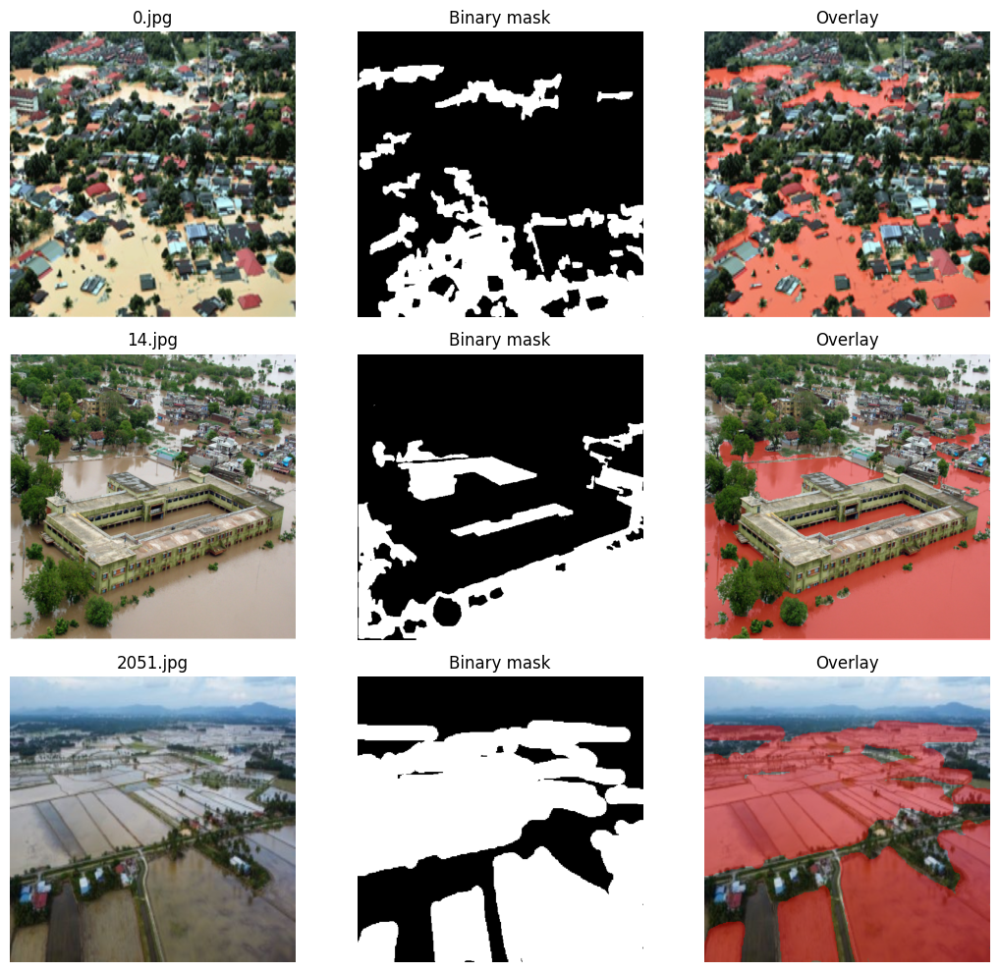

Preprocessing cache: /content/d3_common_flood_cache/310cfcc406f1bd6a


In [3]:
cache_key = hashlib.sha256((meta.to_csv(index=False) + str(IMAGE_SIZE)).encode()).hexdigest()[:16]
cache_dir = CACHE_ROOT/cache_key
cache_dir.mkdir(exist_ok=True)
imgs_file = cache_dir/'images_uint8.npy'
masks_file = cache_dir/'masks_uint8.npy'
complete_file = cache_dir/'COMPLETE'
if not complete_file.is_file():
    img_mm = np.lib.format.open_memmap(imgs_file, mode='w+', dtype=np.uint8, shape=(290, IMAGE_SIZE[1], IMAGE_SIZE[0], 3))
    mask_mm = np.lib.format.open_memmap(masks_file, mode='w+', dtype=np.uint8, shape=(290, IMAGE_SIZE[1], IMAGE_SIZE[0]))
    for i,r in enumerate(meta.itertuples()):
        with Image.open(DATA_ROOT_LOCAL/'Image'/r.Image) as im:
            img_mm[i] = np.asarray(im.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR))
        with Image.open(DATA_ROOT_LOCAL/'Mask'/r.Mask) as mk:
            mask_mm[i] = (np.asarray(mk.convert('L').resize(IMAGE_SIZE, Image.Resampling.NEAREST)) > 0).astype(np.uint8)
    img_mm.flush(); mask_mm.flush(); del img_mm, mask_mm
    complete_file.write_text(cache_key)
IMAGES = np.load(imgs_file, mmap_mode='r')
MASKS = np.load(masks_file, mmap_mode='r')
assert IMAGES.shape == (290,512,512,3) and MASKS.shape == (290,512,512)
assert np.isin(np.unique(MASKS[0]), [0,1]).all()

fig, axs = plt.subplots(3,3,figsize=(11,10))
for ri, idx in enumerate([0, 14, 100]):
    im=np.asarray(IMAGES[idx]); ma=np.asarray(MASKS[idx])
    overlay=im.astype(np.float32)/255.0
    overlay[ma>0] = 0.6*overlay[ma>0] + 0.4*np.array([1,0,0])
    for ci, array in enumerate([im, ma, overlay]):
        axs[ri,ci].imshow(array, cmap='gray' if ci==1 else None, vmin=0 if ci==1 else None, vmax=1 if ci==1 else None)
        axs[ri,ci].axis('off')
    axs[ri,0].set_title(str(meta.iloc[idx].Image)); axs[ri,1].set_title('Binary mask'); axs[ri,2].set_title('Overlay')
plt.tight_layout(); plt.savefig(PROJECT/'data_records'/'dataset_examples.png',dpi=180); plt.show()
print('Preprocessing cache:', cache_dir)

## Block 4 — One deterministic train/validation/test split and three common heterogeneous clients

,Client,Total,Labeled,Unlabeled,Mean flood coverage (%),Aggregation weight
0,1,108,22,86,24.850836,0.497696
1,2,51,10,41,56.731976,0.235023
2,3,58,12,46,55.540920,0.267281


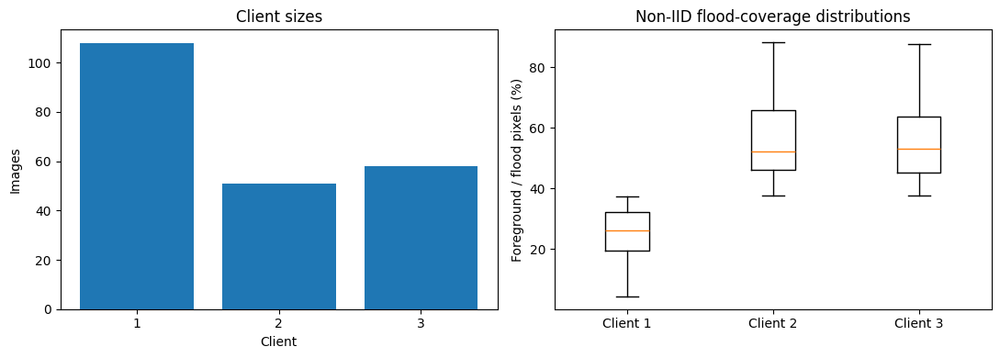

Common split and client allocation saved under /content/drive/MyDrive/DLP_Project/D3_CONTROLLED_RERUN_2026/data_records


In [4]:
N = len(meta)
perm = torch.randperm(N, generator=torch.Generator().manual_seed(SEED_SPLIT)).tolist()
TRAIN_IDS = perm[:217]
TEST_IDS = perm[217:261]
VAL_IDS = perm[261:]
assert [len(TRAIN_IDS),len(VAL_IDS),len(TEST_IDS)] == [217,29,44]
assert len(set(TRAIN_IDS + VAL_IDS + TEST_IDS)) == 290

# Exactly matches the ResNet notebook's flood-coverage-skewed partition idea.
coverage = np.asarray(MASKS[:], dtype=np.float32).mean(axis=(1,2))
train_sorted = sorted(TRAIN_IDS, key=lambda i: coverage[i])  # stable order on ties
c1 = train_sorted[:108]
remaining = np.random.default_rng(SEED_SPLIT).permutation(np.asarray(train_sorted[108:])).tolist()
CLIENT_IDS = [c1, remaining[:51], remaining[51:]]
assert [len(x) for x in CLIENT_IDS] == CLIENT_SIZES
assert set(sum(CLIENT_IDS, [])) == set(TRAIN_IDS)

LABELED_IDS, UNLABELED_IDS = [], []
for i, ids in enumerate(CLIENT_IDS):
    perm_c = torch.randperm(len(ids), generator=torch.Generator().manual_seed(SEED_SPLIT + 100 + i)).tolist()
    labels = [ids[j] for j in perm_c[:LABELED_COUNTS[i]]]
    unlabels = [ids[j] for j in perm_c[LABELED_COUNTS[i]:]]
    LABELED_IDS.append(labels); UNLABELED_IDS.append(unlabels)
assert [len(a) for a in LABELED_IDS] == LABELED_COUNTS
assert sum(map(len,UNLABELED_IDS)) == 173

# Record the exact filenames and masks. Shared by all architectures.
def export_split(ids, filename):
    x=meta.iloc[ids].copy().reset_index(drop=True)
    x.insert(0,'dataset_index',ids)
    x['flood_fraction']=[float(coverage[i]) for i in ids]
    x.to_csv(records/filename,index=False)
export_split(TRAIN_IDS,'train.csv'); export_split(VAL_IDS,'val.csv'); export_split(TEST_IDS,'test.csv')
for k in range(3):
    export_split(CLIENT_IDS[k],f'client_{k+1}_all.csv')
    export_split(LABELED_IDS[k],f'client_{k+1}_labeled.csv')
    export_split(UNLABELED_IDS[k],f'client_{k+1}_unlabeled.csv')

part_summary=pd.DataFrame([{'Client':i+1,'Total':len(CLIENT_IDS[i]),'Labeled':len(LABELED_IDS[i]),
    'Unlabeled':len(UNLABELED_IDS[i]),'Mean flood coverage (%)':100*np.mean(coverage[CLIENT_IDS[i]]),
    'Aggregation weight':len(CLIENT_IDS[i])/217} for i in range(3)])
part_summary.to_csv(records/'client_summary.csv', index=False)
display(part_summary)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(part_summary.Client.astype(str),part_summary.Total,label='Total samples')
axs[0].set(xlabel='Client',ylabel='Images',title='Client sizes')
axs[1].boxplot([100*coverage[x] for x in CLIENT_IDS]);axs[1].set_xticks([1,2,3],['Client 1','Client 2','Client 3'])
axs[1].set(ylabel='Foreground / flood pixels (%)',title='Non-IID flood-coverage distributions')
plt.tight_layout(); plt.savefig(records/'client_partition.png',dpi=180); plt.show()
print('Common split and client allocation saved under',records)

## Block 5 — Shared dataset/loader logic and architecture-specific normalization

In [5]:
class CachedFloodDataset(Dataset):
    def __init__(self, image_npy, mask_npy):
        self.img = np.load(image_npy, mmap_mode='r')
        self.msk = np.load(mask_npy, mmap_mode='r')
    def __len__(self): return len(self.img)
    def __getitem__(self, i):
        # Always return raw [0,1] RGB. Normalization is inside model_preprocess().
        x=torch.from_numpy(np.array(self.img[i], copy=True)).permute(2,0,1).float().div_(255)
        y=torch.from_numpy(np.array(self.msk[i], copy=True)).unsqueeze(0).float()
        return x,y,int(i)

DATASET=CachedFloodDataset(imgs_file,masks_file)
IM_MEAN = torch.tensor([0.485,0.456,0.406],device=DEVICE).view(1,3,1,1)
IM_STD  = torch.tensor([0.229,0.224,0.225],device=DEVICE).view(1,3,1,1)

def model_preprocess(images_01, arch):
    # ResNet-50 ImageNet encoder expects standardized RGB; U-Net receives raw 0..1 RGB.
    return (images_01-IM_MEAN)/IM_STD if arch=='resnet' else images_01

def build_loader(ids,batch_size,shuffle=False,seed=0):
    return DataLoader(Subset(DATASET, list(ids)), batch_size=batch_size,
        shuffle=shuffle, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=False,
        generator=torch.Generator().manual_seed(int(seed)) if shuffle else None)

def loop_next(iterator,loader):
    try: return next(iterator), iterator
    except StopIteration:
        iterator=iter(loader); return next(iterator),iterator

# Input validity checks
batch=next(iter(build_loader(TRAIN_IDS,2)))
assert batch[0].shape == (2,3,512,512) and batch[1].shape == (2,1,512,512)
assert torch.isfinite(batch[0]).all() and (batch[1].min()>=0 and batch[1].max()<=1)
print('Raw RGB range:', float(batch[0].min()), float(batch[0].max()))
print('Shared preprocessed input and masks validated.')

Raw RGB range: 0.0 0.9960784316062927
Shared preprocessed input and masks validated.


## Block 6 — Two architectures from your notebooks: pretrained ResNet-50/U-Net-style decoder; scratch U-Net

In [6]:
class DoubleConv(nn.Module):
    def __init__(self,inp,out):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(inp,out,3,padding=1,bias=False),nn.BatchNorm2d(out),nn.ReLU(inplace=True),
            nn.Conv2d(out,out,3,padding=1,bias=False),nn.BatchNorm2d(out),nn.ReLU(inplace=True))
    def forward(self,x):return self.net(x)

class ResDecoder(nn.Module):
    def __init__(self, channels, skip, output):
        super().__init__(); self.block=DoubleConv(channels+skip,output)
    def forward(self,x,skip):
        x=F.interpolate(x,size=skip.shape[-2:],mode='bilinear',align_corners=False)
        return self.block(torch.cat((x,skip),1))

class ResNet50UNet(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()
        enc=resnet50(weights=ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        self.stem=nn.Sequential(enc.conv1,enc.bn1,enc.relu)
        self.pool=enc.maxpool
        self.encoder1=enc.layer1;self.encoder2=enc.layer2
        self.encoder3=enc.layer3;self.encoder4=enc.layer4
        self.decoder4=ResDecoder(2048,1024,256)
        self.decoder3=ResDecoder(256,512,128)
        self.decoder2=ResDecoder(128,256,64)
        self.decoder1=ResDecoder(64,64,32)
        self.final_decoder=DoubleConv(32,16)
        self.head=nn.Conv2d(16,1,1)
    def forward(self,x):
        out_size=x.shape[-2:]
        stem=self.stem(x)
        e1=self.encoder1(self.pool(stem));e2=self.encoder2(e1)
        e3=self.encoder3(e2);e4=self.encoder4(e3)
        x=self.decoder4(e4,e3); x=self.decoder3(x,e2)
        x=self.decoder2(x,e1);x=self.decoder1(x,stem)
        return self.head(self.final_decoder(F.interpolate(x,size=out_size,mode='bilinear',align_corners=False)))

class UpConv(nn.Module):
    def __init__(self, in_ch,out_ch):
        super().__init__()
        self.up=nn.ConvTranspose2d(in_ch,in_ch//2,2,stride=2)
        self.conv=DoubleConv(in_ch,out_ch)
    def forward(self,x,skip):
        x=self.up(x)
        if x.shape[-2:]!=skip.shape[-2:]:x=F.interpolate(x,size=skip.shape[-2:],mode='bilinear',align_corners=False)
        return self.conv(torch.cat((skip,x),1))

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool=nn.MaxPool2d(2)
        self.down1=DoubleConv(3,64);self.down2=DoubleConv(64,128)
        self.down3=DoubleConv(128,256);self.down4=DoubleConv(256,512)
        self.down5=DoubleConv(512,1024)
        self.up1=UpConv(1024,512);self.up2=UpConv(512,256)
        self.up3=UpConv(256,128);self.up4=UpConv(128,64)
        self.final=nn.Conv2d(64,1,1)
    def forward(self,x):
        x1=self.down1(x);x2=self.down2(self.pool(x1))
        x3=self.down3(self.pool(x2));x4=self.down4(self.pool(x3))
        x5=self.down5(self.pool(x4));x=self.up1(x5,x4)
        x=self.up2(x,x3);x=self.up3(x,x2);x=self.up4(x,x1)
        return self.final(x)

def new_model(arch, pretrained=False):
    if arch=='resnet':return ResNet50UNet(pretrained=pretrained)
    if arch=='unet':return UNet()
    raise ValueError(arch)

def clone_cpu_state(state):
    return {k:v.detach().cpu().clone() for k,v in state.items()}

def get_initial_state(arch,seed):
    path=PROJECT/'initial_states'/f'{arch}_seed_{seed}.pt'
    path.parent.mkdir(parents=True,exist_ok=True)
    if path.exists(): return torch.load(path,map_location='cpu',weights_only=False)
    seed_everything(seed)
    model=new_model(arch,pretrained=(arch=='resnet'))
    state=clone_cpu_state(model.state_dict())
    torch.save(state,path);del model
    return state

for arch in ['resnet','unet']:
    state=get_initial_state(arch, MODEL_SEEDS[0])
    model=new_model(arch,pretrained=False)
    assert model.load_state_dict(state).missing_keys==[]
    param_n=sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{arch}: {param_n:,} trainable parameters')
    del model,state
# Both architectures are initialized ONCE per seed, and initial states reused across experiments.
gc.collect()

resnet: 32,520,977 trainable parameters
unet: 31,037,633 trainable parameters


38

## Block 6a — GPU preflight: forward/backward + teacher memory before any expensive training

In [7]:
# Fast, early check: both architectures must support a two-image forward/backward step.
# This does not train a model or alter any saved experiment checkpoints.
for arch in ['resnet','unet']:
    seed_everything(SEED_SPLIT)
    trial=new_model(arch,pretrained=False).to(DEVICE).train()
    trial.load_state_dict(get_initial_state(arch,MODEL_SEEDS[0]))
    trial_teacher=new_model(arch,pretrained=False).to(DEVICE).eval()
    trial_teacher.load_state_dict(trial.state_dict())
    trial_teacher.requires_grad_(False)
    torch.cuda.reset_peak_memory_stats()
    test_batch=next(iter(build_loader(TRAIN_IDS,MICRO_BATCH)))
    bx=test_batch[0].to(DEVICE);by=test_batch[1].to(DEVICE)
    try:
        with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
            pred=trial(model_preprocess(bx,arch))
            with torch.no_grad():t_pred=trial_teacher(model_preprocess(bx,arch))
            loss=F.binary_cross_entropy_with_logits(pred.float(),by)
        assert pred.shape == by.shape and t_pred.shape == by.shape
        assert torch.isfinite(loss),'Nonfinite preflight loss'
        loss.backward()
        print(arch, '| preflight OK | loss:',round(float(loss),5),
              '| peak allocated GiB:',round(torch.cuda.max_memory_allocated()/2**30,3))
    finally:
        del trial,trial_teacher,bx,by,pred,t_pred,loss,test_batch
        gc.collect();torch.cuda.empty_cache()
print('GPU preflight completed; if a CUDA OOM occurs here, set MICRO_BATCH=1, restart, and use a fresh output folder.')

/tmp/ipykernel_8132/1386222392.py:21: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print(arch, '| preflight OK | loss:',round(float(loss),5),


resnet | preflight OK | loss: 0.74938 | peak allocated GiB: 1.491
unet | preflight OK | loss: 0.70581 | peak allocated GiB: 2.236
GPU preflight completed; if a CUDA OOM occurs here, set MICRO_BATCH=1, restart, and use a fresh output folder.


## Block 7 — Pooled confusion counts, all evaluation metrics, and validation/test evaluation

In [8]:
METRICS=['iou','f1','precision','recall','pixel_accuracy']

def counts_to_metrics(tp,fp,fn,tn):
    total=tp+fp+fn+tn
    return {'iou':tp/max(tp+fp+fn,1),'precision':tp/max(tp+fp,1),
            'recall':tp/max(tp+fn,1),'f1':2*tp/max(2*tp+fp+fn,1),
            'pixel_accuracy':(tp+tn)/max(total,1),
            'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn)}

def model_evaluate(model,ids,arch,per_image=False):
    loader=build_loader(ids,VAL_BATCH,shuffle=False)
    model.eval();tp=fp=fn=tn=0
    loss_sum=0.0;count=0;image_records=[]
    with torch.inference_mode():
        for raw,masks,idxs in loader:
            x=model_preprocess(raw.to(DEVICE,non_blocking=True),arch)
            targets=masks.to(DEVICE,non_blocking=True)
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                logits=model(x)
                loss=F.binary_cross_entropy_with_logits(logits.float(),targets)
            prob=torch.sigmoid(logits.float())
            guess=(prob >= PRED_THRESHOLD); truth=(targets>=0.5)
            tp+=int((guess & truth).sum());fp+=int((guess & ~truth).sum())
            fn+=int((~guess & truth).sum());tn+=int((~guess & ~truth).sum())
            count+=len(raw);loss_sum+=float(loss)*len(raw)
            if per_image:
                for bi,idx in enumerate(idxs.tolist()):
                    p=guess[bi];t=truth[bi]
                    a=int((p&t).sum());b=int((p&~t).sum());c=int((~p&t).sum());d=int((~p&~t).sum())
                    image_records.append({'dataset_index':idx,'image':meta.iloc[idx].Image,**counts_to_metrics(a,b,c,d)})
    res=counts_to_metrics(tp,fp,fn,tn)
    res['loss']=loss_sum/max(count,1);res['num_images']=int(count)
    return (res,pd.DataFrame(image_records)) if per_image else res

# Metric self-tests
assert counts_to_metrics(10,0,0,10)['iou']==1.0
assert abs(counts_to_metrics(10,10,0,0)['precision']-0.5)<1e-12
print('Metric definitions passed elementary unit tests; all metrics pooled over pixels.')

Metric definitions passed elementary unit tests; all metrics pooled over pixels.


## Block 8 — FedAvg aggregation, FedProx anchor, pseudo-label filtering, EMA, and delayed unsupervised-loss ramp

In [9]:
STRONG_COLOR=ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2,hue=0.05)

def ramp_weight(round_id):
    if round_id<=5:return 0.0
    if round_id>=15:return 1.0
    return 0.1*(round_id-5)

assert ramp_weight(1)==0 and ramp_weight(6)==0.1 and ramp_weight(15)==1.0

def ema_update(teacher,student,decay):
    with torch.no_grad():
        for tp,sp in zip(teacher.parameters(),student.parameters()):
            tp.mul_(decay).add_(sp,alpha=1-decay)
        for tb,sb in zip(teacher.buffers(),student.buffers()):
            if tb.is_floating_point():tb.mul_(decay).add_(sb,alpha=1-decay)
            else:tb.copy_(sb)

def fedprox_loss(local_model,anchor):
    result=torch.zeros((),dtype=torch.float32,device=DEVICE)
    for p,g in zip(local_model.parameters(),anchor):
        result=result+(p-g).square().sum()
    return (MU/2)*result

def fedavg_states(states,counts):
    assert len(states)==len(counts)>0
    w=np.asarray(counts,dtype=float);w/=w.sum()
    out={}
    for name,v in states[0].items():
        if torch.is_floating_point(v):
            a=torch.zeros_like(v)
            for s,weight in zip(states,w):a.add_(s[name],alpha=float(weight))
            if not torch.isfinite(a).all():raise FloatingPointError('Invalid state '+name)
            out[name]=a
        else:
            # Same batch norm integer-buffer rule across ALL configurations (first client).
            out[name]=v.clone()
    return out

# Original ResNet implementation used BCE masked sum / all pixels; here that reduction
# is consistently applied to both ResNet and U-Net. This makes new U-Net numbers
# NOT the same experiment as in the original U-Net notebook.
print('Ramped unsupervised weights:',[(r,round(ramp_weight(r),2)) for r in [1,5,6,10,15,60]])

Ramped unsupervised weights: [(1, 0.0), (5, 0.0), (6, 0.1), (10, 0.5), (15, 1.0), (60, 1.0)]


## Block 9 — Artifact saving and experiment manifest; safe resume

In [10]:
def atomic_torch_save(value,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    torch.save(value,tmp)
    os.replace(tmp,path)

def atomic_json_save(value,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(value,indent=2,default=float))
    os.replace(tmp,path)

RUN_CONFIG={
    'version':ALGORITHM_VERSION,'split_seed':SEED_SPLIT,'image_size':IMAGE_SIZE,
    'client_sizes':CLIENT_SIZES,'client_steps':CLIENT_STEPS,'labeled_counts':LABELED_COUNTS,
    'batch_size':BATCH_SIZE,'micro_batch':MICRO_BATCH,'val_batch':VAL_BATCH,
    'lr':LR,'betas':BETAS,'central_epochs':CENTRAL_EPOCHS,'fed_rounds':FED_ROUNDS,
    'mu':MU,'confidence':PSEUDO_CONFIDENCE,'ema_max':MAX_EMA_DECAY,
    'prediction_threshold':PRED_THRESHOLD,'amp':AMP,
    'input_normalization':{'resnet':'ImageNet RGB mean/std','unet':'RGB scaled to [0,1]'},
    'unsupervised_reduction':'masked BCE sum / total unlabeled pixels',
    'validation_checkpoint_selection':'max pooled validation IoU',
    'dataset_zip':ZIP_PATH.name,'metadata_sha256':hashlib.sha256(meta.to_csv(index=False).encode()).hexdigest(),
    'training_budget_note':'fixed steps [14,7,8] per client per FL round for all FL configurations; 60 centralized epochs',
    'batchnorm_integer_buffer_aggregation':'first client across all FL experiments'
}
manifest=PROJECT/'run_manifest.json'
if manifest.exists():
    previous=json.loads(manifest.read_text())
    assert previous==json.loads(json.dumps(RUN_CONFIG)),('Existing checkpoints use different hyperparameters or data. '
        'Use a NEW output folder when changing experimental settings. Do not mix runs.')
else:atomic_json_save(RUN_CONFIG,manifest)

def run_dir(key,seed):
    d=PROJECT/'experiments'/key/f'seed_{seed}'
    d.mkdir(parents=True,exist_ok=True)
    return d

def round_seed(seed, round_id, client_id=0):
    # Round-level deterministic restarts; no reliance on RNG state saved inside a round.
    return int(seed)*100000+int(round_id)*100+int(client_id)

def get_best_model(arch,key,seed):
    best=run_dir(key,seed)/'best.pt'
    assert best.exists(),f'Missing best checkpoint for {key} seed={seed}'
    state=torch.load(best,map_location='cpu',weights_only=False)['model_state']
    model=new_model(arch,pretrained=False).to(DEVICE)
    model.load_state_dict(state);model.eval()
    return model

print('Experiment manifest saved:',manifest)

Experiment manifest saved: /content/drive/MyDrive/DLP_Project/D3_CONTROLLED_RERUN_2026/run_manifest.json


## Block 10 — Common local trainer for FedAvg / FedProx, full labels / 20% labels / student–teacher SSL

In [11]:
def train_local_client(arch,global_state,client_id,round_id,model_seed,optim_kind='fedavg',mode='full'):
    assert optim_kind in ['fedavg','fedprox'] and mode in ['full','labeled','ssl']
    seed_everything(round_seed(model_seed,round_id,client_id+1))
    student=new_model(arch,pretrained=False).to(DEVICE)
    student.load_state_dict(global_state);student.train()
    teacher=None;anchor=[]
    if mode=='ssl':
        teacher=new_model(arch,pretrained=False).to(DEVICE)
        teacher.load_state_dict(global_state)
        teacher.requires_grad_(False);teacher.eval()
    if optim_kind=='fedprox':
        anchor=[p.detach().clone() for p in student.parameters()]

    opt=torch.optim.Adam(student.parameters(),lr=LR,betas=BETAS)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    labeled_ids=CLIENT_IDS[client_id] if mode=='full' else LABELED_IDS[client_id]
    l_loader=build_loader(labeled_ids,BATCH_SIZE,shuffle=True,
        seed=round_seed(model_seed,round_id,client_id+1)+11)
    l_iterator=iter(l_loader)
    u_loader=None;u_iterator=None
    if mode=='ssl':
        u_loader=build_loader(UNLABELED_IDS[client_id],BATCH_SIZE,shuffle=True,
            seed=round_seed(model_seed,round_id,client_id+1)+23)
        u_iterator=iter(u_loader)

    weight=ramp_weight(round_id) if mode=='ssl' else 0.
    logs={'supervised':0.,'unsupervised':0.,'proximal':0.,'accepted_pixels':0,
          'evaluated_pixels':0,'skipped_amp_steps':0,'local_steps':CLIENT_STEPS[client_id]}
    for step in range(CLIENT_STEPS[client_id]):
        (lrgb,lmask,_),l_iterator=loop_next(l_iterator,l_loader)
        if mode=='ssl':
            (urgb,_,_),u_iterator=loop_next(u_iterator,u_loader)
        opt.zero_grad(set_to_none=True)
        labeled_count=len(lrgb)
        # Compute gradients for effective batch (8) in physical microbatches (2).
        for j in range(0,labeled_count,MICRO_BATCH):
            raw=lrgb[j:j+MICRO_BATCH].to(DEVICE,non_blocking=True)
            truth=lmask[j:j+MICRO_BATCH].to(DEVICE,non_blocking=True)
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                logits=student(model_preprocess(raw,arch))
                loss_sup=F.binary_cross_entropy_with_logits(logits.float(),truth)
            fraction=len(raw)/labeled_count
            assert torch.isfinite(loss_sup), 'Nonfinite supervised loss'
            scaler.scale(loss_sup*fraction).backward()
            logs['supervised']+=float(loss_sup.detach())*fraction
            del raw,truth,logits,loss_sup

        if mode=='ssl' and weight>0:
            total_unlabeled_pixels=len(urgb)*IMAGE_SIZE[0]*IMAGE_SIZE[1]
            for j in range(0,len(urgb),MICRO_BATCH):
                weak=urgb[j:j+MICRO_BATCH].to(DEVICE,non_blocking=True)
                with torch.no_grad():
                    with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                        teacher_logits=teacher(model_preprocess(weak,arch))
                    p=torch.sigmoid(teacher_logits.float())
                    accepted=(torch.maximum(p,1-p)>=PSEUDO_CONFIDENCE)
                    pseudo=(p>=0.5).float()
                # IMPORTANT: ColorJitter acts on unnormalized [0,1] RGB, then normalize for network.
                strong=torch.stack([STRONG_COLOR(im) for im in weak]).clamp(0,1)
                with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                    student_logits=student(model_preprocess(strong,arch))
                    pixel_bce=F.binary_cross_entropy_with_logits(student_logits.float(),pseudo,reduction='none')
                    loss_uns=(pixel_bce*accepted.float()).sum()/total_unlabeled_pixels
                assert torch.isfinite(loss_uns),'Nonfinite unsupervised loss'
                scaler.scale(weight*loss_uns).backward()
                logs['unsupervised']+=float(loss_uns.detach())
                logs['accepted_pixels']+=int(accepted.sum())
                logs['evaluated_pixels']+=int(accepted.numel())
                del weak,teacher_logits,p,accepted,pseudo,strong,student_logits,pixel_bce,loss_uns

        if optim_kind=='fedprox':
            prox=fedprox_loss(student,anchor)
            assert torch.isfinite(prox),'Nonfinite FedProx penalty'
            scaler.scale(prox).backward()
            logs['proximal']+=float(prox.detach())
            del prox
        scaler.unscale_(opt)
        # Let GradScaler skip an overflowing optimizer step and reduce its loss scale.
        # The run continues; the number of skips is logged for diagnostics.
        if not AMP and any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in student.parameters()):
            raise FloatingPointError(f'Nonfinite gradient in {arch} client {client_id+1} round {round_id}')
        previous_scale=scaler.get_scale()
        scaler.step(opt);scaler.update()
        successful_step=(not AMP) or (scaler.get_scale()>=previous_scale)
        if not successful_step:logs['skipped_amp_steps']+=1
        if teacher is not None and successful_step:
            step_global=(round_id-1)*sum(CLIENT_STEPS)+step+1
            decay=min(MAX_EMA_DECAY,1.-1./(step_global+1.))
            ema_update(teacher,student,decay)

    result=clone_cpu_state(student.state_dict())
    logs['accepted_fraction']=(logs['accepted_pixels']/logs['evaluated_pixels']
                               if logs['evaluated_pixels'] else 0.)
    for k in ['supervised','unsupervised','proximal']:
        logs[k]/=max(CLIENT_STEPS[client_id],1)
    del student,teacher,opt,scaler,anchor
    gc.collect();torch.cuda.empty_cache()
    return result,logs

## Block 11 — Federated experiment runner: same clients, aggregation weights, local steps, and test protocol

In [12]:
def fit_federated(key,arch,optim_kind,mode,seed):
    out=run_dir(key,seed)
    last_file=out/'last.pt';best_file=out/'best.pt'
    config={'key':key,'arch':arch,'optimizer':optim_kind,'mode':mode,'seed':seed,'global_config':RUN_CONFIG}
    if last_file.exists():
        ck=torch.load(last_file,map_location='cpu',weights_only=False)
        assert ck['config']==config,'Checkpoint/config mismatch; use a fresh output folder.'
        state=ck['model_state']; start_round=ck['round']+1
        best_iou=ck['best_iou'];best_round=ck['best_round'];history=ck['history']
        elapsed=ck.get('elapsed_seconds',0.)
        if start_round>FED_ROUNDS:print(f'SKIP {key} seed={seed}: all rounds completed')
        else:print(f'RESUME {key} seed={seed} at round {start_round}')
    else:
        state=get_initial_state(arch,seed)
        start_round=1;best_iou=-1.;best_round=0;history=[];elapsed=0.
        print(f'NEW {key} seed={seed}')

    for rnd in range(start_round,FED_ROUNDS+1):
        torch.cuda.reset_peak_memory_stats()
        started=time.perf_counter();new_states=[];logs=[]
        for k in range(3):
            client_state,log=train_local_client(arch,state,k,rnd,seed,optim_kind,mode)
            new_states.append(client_state);logs.append(log)
        state=fedavg_states(new_states,CLIENT_SIZES)
        del new_states
        val_model=new_model(arch,pretrained=False).to(DEVICE)
        val_model.load_state_dict(state)
        validation=model_evaluate(val_model,VAL_IDS,arch)
        del val_model;torch.cuda.empty_cache()
        duration=time.perf_counter()-started;elapsed+=duration
        peak_training_gib=torch.cuda.max_memory_allocated()/2**30
        row={'round':rnd,'elapsed_seconds':duration,'training_peak_allocated_gib':peak_training_gib,
             'unsup_weight':ramp_weight(rnd) if mode=='ssl' else 0.,
             **{f'val_{x}':validation[x] for x in ['loss']+METRICS}}
        for k,log in enumerate(logs):
            for field,value in log.items():row[f'client{k+1}_{field}']=value
        history.append(row)
        if validation['iou']>best_iou:
            best_iou=validation['iou'];best_round=rnd
            atomic_torch_save({'config':config,'round':rnd,'model_state':state,
                               'best_iou':best_iou},best_file)
        atomic_torch_save({'config':config,'round':rnd,'model_state':state,
                           'best_iou':best_iou,'best_round':best_round,'history':history,
                           'elapsed_seconds':elapsed},last_file)
        pd.DataFrame(history).to_csv(out/'validation_history.csv',index=False)
        print(f'{key:<24} | R{rnd:02d}/{FED_ROUNDS} | val IoU={validation["iou"]:.4f}'
              f' F1={validation["f1"]:.4f} | {duration:.1f}s'
              + (' | BEST' if best_round==rnd else ''),flush=True)
        gc.collect();torch.cuda.empty_cache()
    assert best_file.exists()
    return {'key':key,'seed':seed,'best_round':best_round,'best_validation_iou':best_iou}

## Block 12 — Centralized ResNet reference (same train/validation/test, 60 complete epochs, validation-selected best)

In [13]:
def fit_centralized(seed):
    arch='resnet';key='resnet_central_full'
    out=run_dir(key,seed);last_file=out/'last.pt';best_file=out/'best.pt'
    config={'key':key,'arch':arch,'seed':seed,'global_config':RUN_CONFIG}
    model=new_model(arch,pretrained=False).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=LR,betas=BETAS)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    if last_file.exists():
        ck=torch.load(last_file,map_location='cpu',weights_only=False)
        assert ck['config']==config,'Centralized checkpoint/config mismatch'
        model.load_state_dict(ck['model_state'])
        optimizer.load_state_dict(ck['optimizer_state']);scaler.load_state_dict(ck['scaler_state'])
        start_epoch=ck['epoch']+1; best_iou=ck['best_iou']; best_epoch=ck['best_epoch']
        hist=ck['history'];elapsed=ck.get('elapsed_seconds',0.)
        print('RESUME central from epoch',start_epoch)
    else:
        model.load_state_dict(get_initial_state(arch,seed))
        start_epoch=1;best_iou=-1.;best_epoch=0;hist=[];elapsed=0.
        print('NEW centralized ResNet seed',seed)

    for epoch in range(start_epoch,CENTRAL_EPOCHS+1):
        torch.cuda.reset_peak_memory_stats()
        t0=time.perf_counter()
        seed_everything(round_seed(seed,epoch,0))
        loader=build_loader(TRAIN_IDS,BATCH_SIZE,shuffle=True,seed=round_seed(seed,epoch,0)+11)
        model.train();trainloss=0.;seen=0
        for imgs,masks,_ in loader:
            optimizer.zero_grad(set_to_none=True)
            batchn=len(imgs)
            for j in range(0,batchn,MICRO_BATCH):
                x=imgs[j:j+MICRO_BATCH].to(DEVICE,non_blocking=True)
                y=masks[j:j+MICRO_BATCH].to(DEVICE,non_blocking=True)
                with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                    logits=model(model_preprocess(x,arch))
                    loss=F.binary_cross_entropy_with_logits(logits.float(),y)
                fraction=len(x)/batchn
                assert torch.isfinite(loss)
                scaler.scale(loss*fraction).backward()
                trainloss+=float(loss.detach())*len(x);seen+=len(x)
                del x,y,logits,loss
            scaler.unscale_(optimizer)
            if not AMP and any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in model.parameters()):
                raise FloatingPointError('Nonfinite centralized gradients')
            scaler.step(optimizer);scaler.update()
        val=model_evaluate(model,VAL_IDS,arch)
        delta=time.perf_counter()-t0;elapsed+=delta
        row={'epoch':epoch,'train_loss':trainloss/max(seen,1),'elapsed_seconds':delta,
             'training_peak_allocated_gib':torch.cuda.max_memory_allocated()/2**30,
             **{f'val_{x}':val[x] for x in ['loss']+METRICS}}
        hist.append(row)
        if val['iou']>best_iou:
            best_iou=val['iou'];best_epoch=epoch
            atomic_torch_save({'config':config,'epoch':epoch,
                               'model_state':clone_cpu_state(model.state_dict()),
                               'best_iou':best_iou},best_file)
        # Keep Adam state so a resumed central run has the same optimizer history.
        atomic_torch_save({'config':config,'epoch':epoch,'model_state':clone_cpu_state(model.state_dict()),
                           'optimizer_state':optimizer.state_dict(),'scaler_state':scaler.state_dict(),
                           'best_iou':best_iou,'best_epoch':best_epoch,'history':hist,
                           'elapsed_seconds':elapsed},last_file)
        pd.DataFrame(hist).to_csv(out/'validation_history.csv',index=False)
        print(f'CENTRAL | E{epoch:02d}/{CENTRAL_EPOCHS} | val IoU={val["iou"]:.4f}'
              f' F1={val["f1"]:.4f} | {delta:.1f}s' + (' | BEST' if best_epoch==epoch else ''),flush=True)
    del model,optimizer,scaler;gc.collect();torch.cuda.empty_cache()
    assert best_file.exists()
    return {'key':key,'seed':seed,'best_epoch':best_epoch,'best_validation_iou':best_iou}

## Block 13 — All nine experiment definitions and batch execution (safe to click **Run all**)

In [14]:
EXPERIMENTS=[
    {'key':'resnet_central_full','arch':'resnet','kind':'central','mode':'full','label_fraction':'100%'},
    {'key':'resnet_fedavg_full','arch':'resnet','kind':'fedavg','mode':'full','label_fraction':'100%'},
    {'key':'resnet_fedavg_labeled20','arch':'resnet','kind':'fedavg','mode':'labeled','label_fraction':'20%'},
    {'key':'resnet_fedavg_ssl20','arch':'resnet','kind':'fedavg','mode':'ssl','label_fraction':'20%'},
    {'key':'resnet_fedprox_labeled20','arch':'resnet','kind':'fedprox','mode':'labeled','label_fraction':'20%'},
    {'key':'resnet_fedprox_ssl20','arch':'resnet','kind':'fedprox','mode':'ssl','label_fraction':'20%'},
    {'key':'unet_fedprox_full','arch':'unet','kind':'fedprox','mode':'full','label_fraction':'100%'},
    {'key':'unet_fedprox_labeled20','arch':'unet','kind':'fedprox','mode':'labeled','label_fraction':'20%'},
    {'key':'unet_fedprox_ssl20','arch':'unet','kind':'fedprox','mode':'ssl','label_fraction':'20%'},
]
assert len({r['key'] for r in EXPERIMENTS})==len(EXPERIMENTS)
print('Planned experiments:')
display(pd.DataFrame(EXPERIMENTS))
print('NOTE: Execution may outlast a single Colab session. On disconnect, rerun all; completed rounds resume.')

Planned experiments:


,key,arch,kind,mode,label_fraction
0,resnet_central_full,resnet,central,full,100%
1,resnet_fedavg_full,resnet,fedavg,full,100%
2,resnet_fedavg_labeled20,resnet,fedavg,labeled,20%
3,resnet_fedavg_ssl20,resnet,fedavg,ssl,20%
4,resnet_fedprox_labeled20,resnet,fedprox,labeled,20%
5,resnet_fedprox_ssl20,resnet,fedprox,ssl,20%
6,unet_fedprox_full,unet,fedprox,full,100%
7,unet_fedprox_labeled20,unet,fedprox,labeled,20%
8,unet_fedprox_ssl20,unet,fedprox,ssl,20%


NOTE: Execution may outlast a single Colab session. On disconnect, rerun all; completed rounds resume.


## Block 14 — START COMPLETE TRAINING: 9 configurations × requested model seeds

In [15]:
# This is the only training call. Do not change the model config halfway through a run.
TRAINING_RUN_REPORT=[]
for seed in MODEL_SEEDS:
    for exp in EXPERIMENTS:
        print('\n'+'='*75+'\nTRAIN',exp['key'],'seed',seed,'\n'+'='*75)
        if exp['kind']=='central': result=fit_centralized(seed)
        else:result=fit_federated(exp['key'],exp['arch'],exp['kind'],exp['mode'],seed)
        TRAINING_RUN_REPORT.append(result)
print('All scheduled training completed.')
display(pd.DataFrame(TRAINING_RUN_REPORT))


TRAIN resnet_central_full seed 42 
RESUME central from epoch 61

TRAIN resnet_fedavg_full seed 42 
SKIP resnet_fedavg_full seed=42: all rounds completed

TRAIN resnet_fedavg_labeled20 seed 42 
SKIP resnet_fedavg_labeled20 seed=42: all rounds completed

TRAIN resnet_fedavg_ssl20 seed 42 
SKIP resnet_fedavg_ssl20 seed=42: all rounds completed

TRAIN resnet_fedprox_labeled20 seed 42 
SKIP resnet_fedprox_labeled20 seed=42: all rounds completed

TRAIN resnet_fedprox_ssl20 seed 42 
RESUME resnet_fedprox_ssl20 seed=42 at round 40
resnet_fedprox_ssl20     | R40/60 | val IoU=0.7362 F1=0.8480 | 78.6s
resnet_fedprox_ssl20     | R41/60 | val IoU=0.7440 F1=0.8532 | 79.7s
resnet_fedprox_ssl20     | R42/60 | val IoU=0.7352 F1=0.8474 | 79.9s
resnet_fedprox_ssl20     | R43/60 | val IoU=0.7334 F1=0.8462 | 80.6s
resnet_fedprox_ssl20     | R44/60 | val IoU=0.7364 F1=0.8482 | 80.7s
resnet_fedprox_ssl20     | R45/60 | val IoU=0.7469 F1=0.8551 | 81.1s
resnet_fedprox_ssl20     | R46/60 | val IoU=0.7261 F1=0.

,key,seed,best_epoch,best_validation_iou,best_round
0,resnet_central_full,42,36.0,0.832155,NaN
1,resnet_fedavg_full,42,NaN,0.813983,58.0
2,resnet_fedavg_labeled20,42,NaN,0.767095,57.0
3,resnet_fedavg_ssl20,42,NaN,0.759060,47.0
4,resnet_fedprox_labeled20,42,NaN,0.751570,57.0
5,resnet_fedprox_ssl20,42,NaN,0.773744,48.0
6,unet_fedprox_full,42,NaN,0.666559,59.0
7,unet_fedprox_labeled20,42,NaN,0.671435,41.0
8,unet_fedprox_ssl20,42,NaN,0.679112,35.0


## Block 15 — Re-evaluate all best checkpoints on validation + held-out test; export **all** metrics

In [16]:
final_rows=[]
per_image_rows=[]
for seed in MODEL_SEEDS:
    for exp in EXPERIMENTS:
        key,arch=exp['key'],exp['arch'];directory=run_dir(key,seed)
        last=torch.load(directory/'last.pt',map_location='cpu',weights_only=False)
        if exp['kind']=='central':
            assert last['epoch']==CENTRAL_EPOCHS
        else:
            assert last['round']==FED_ROUNDS
        model=get_best_model(arch,key,seed)
        val_metrics=model_evaluate(model,VAL_IDS,arch)
        torch.cuda.reset_peak_memory_stats()
        test_metrics,per_image=model_evaluate(model,TEST_IDS,arch,per_image=True)
        peak_eval=torch.cuda.max_memory_allocated()/2**30
        best=torch.load(directory/'best.pt',map_location='cpu',weights_only=False)
        assert abs(best['best_iou']-val_metrics['iou'])<5e-5,('Best checkpoint did not reproduce saved validation IoU',key)
        row={'experiment':key,'architecture':arch,'federated_optimizer':exp['kind'],
             'training_mode':exp['mode'],'label_fraction':exp['label_fraction'],
             'seed':seed,'best_epoch_or_round':best.get('epoch',best.get('round')),
             'validation_iou':val_metrics['iou'],'validation_f1':val_metrics['f1'],
             'train_time_s_logged':last.get('elapsed_seconds'),
             'training_peak_allocated_gib_max':pd.read_csv(directory/'validation_history.csv')['training_peak_allocated_gib'].max(),
             'eval_peak_allocated_gib':peak_eval,
             'parameters':sum(p.numel() for p in model.parameters() if p.requires_grad),
             **{f'test_{m}':test_metrics[m] for m in ['loss']+METRICS},
             **{f'test_{q}':test_metrics[q] for q in ['tp','fp','fn','tn']}}
        final_rows.append(row)
        per_image.insert(0,'seed',seed);per_image.insert(0,'experiment',key)
        per_image.to_csv(directory/'test_per_image.csv',index=False)
        per_image_rows.append(per_image)
        atomic_json_save({'configuration':exp,'seed':seed,'validation':val_metrics,
                         'test':test_metrics,'best_round_or_epoch':row['best_epoch_or_round'],
                         'train_time_s_logged':row['train_time_s_logged']},directory/'test_results.json')
        print(f'{key:<27} IoU={test_metrics["iou"]:.5f} F1={test_metrics["f1"]:.5f}'
              f' Precision={test_metrics["precision"]:.5f} Recall={test_metrics["recall"]:.5f}'
              f' Pixel accuracy={test_metrics["pixel_accuracy"]:.5f}')
        del model;gc.collect();torch.cuda.empty_cache()
results_df=pd.DataFrame(final_rows)
results_df.to_csv(PROJECT/'all_results_by_seed.csv',index=False)
all_per_image_df=pd.concat(per_image_rows,ignore_index=True)
all_per_image_df.to_csv(PROJECT/'all_test_per_image.csv',index=False)
display(results_df[['experiment','label_fraction','seed','best_epoch_or_round',
   'test_iou','test_f1','test_precision','test_recall','test_pixel_accuracy']].round(5))

resnet_central_full         IoU=0.80964 F1=0.89481 Precision=0.88277 Recall=0.90717 Pixel accuracy=0.90463
resnet_fedavg_full          IoU=0.81561 F1=0.89844 Precision=0.90949 Recall=0.88766 Pixel accuracy=0.91027
resnet_fedavg_labeled20     IoU=0.79647 F1=0.88670 Precision=0.88910 Recall=0.88432 Pixel accuracy=0.89895
resnet_fedavg_ssl20         IoU=0.80653 F1=0.89291 Precision=0.88277 Recall=0.90329 Pixel accuracy=0.90312
resnet_fedprox_labeled20    IoU=0.78831 F1=0.88163 Precision=0.86096 Recall=0.90331 Pixel accuracy=0.89154
resnet_fedprox_ssl20        IoU=0.80403 F1=0.89137 Precision=0.89817 Recall=0.88468 Pixel accuracy=0.90359
unet_fedprox_full           IoU=0.72438 F1=0.84016 Precision=0.89825 Recall=0.78913 Pixel accuracy=0.86575
unet_fedprox_labeled20      IoU=0.73306 F1=0.84598 Precision=0.86251 Recall=0.83006 Pixel accuracy=0.86485
unet_fedprox_ssl20          IoU=0.73152 F1=0.84495 Precision=0.87257 Recall=0.81902 Pixel accuracy=0.86560


,experiment,label_fraction,seed,best_epoch_or_round,test_iou,test_f1,test_precision,test_recall,test_pixel_accuracy
0,resnet_central_full,100%,42,36,0.80964,0.89481,0.88277,0.90717,0.90463
1,resnet_fedavg_full,100%,42,58,0.81561,0.89844,0.90949,0.88766,0.91027
2,resnet_fedavg_labeled20,20%,42,57,0.79647,0.88670,0.88910,0.88432,0.89895
3,resnet_fedavg_ssl20,20%,42,47,0.80653,0.89291,0.88277,0.90329,0.90312
4,resnet_fedprox_labeled20,20%,42,57,0.78831,0.88163,0.86096,0.90331,0.89154
5,resnet_fedprox_ssl20,20%,42,48,0.80403,0.89137,0.89817,0.88468,0.90359
6,unet_fedprox_full,100%,42,59,0.72438,0.84016,0.89825,0.78913,0.86575
7,unet_fedprox_labeled20,20%,42,41,0.73306,0.84598,0.86251,0.83006,0.86485
8,unet_fedprox_ssl20,20%,42,35,0.73152,0.84495,0.87257,0.81902,0.86560


## Block 16 — If repeated seeds: mean and standard deviation; top-performing configurations

In [17]:
metric_cols=['test_iou','test_f1','test_precision','test_recall','test_pixel_accuracy','test_loss']
summary=results_df.groupby('experiment',as_index=False).agg(
    n=('seed','count'),
    **{f'{col}_mean':(col,'mean') for col in metric_cols},
    **{f'{col}_std':(col,'std') for col in metric_cols},
)
# A std is undefined for n=1; leave NaN rather than inventing error bars.
summary.to_csv(PROJECT/'metrics_mean_std.csv',index=False)
display(summary.round(5))
for label,sub in [('All ResNet',results_df[results_df.architecture=='resnet']),
                  ('ResNet with 20% labels',results_df[(results_df.architecture=='resnet')&(results_df.label_fraction=='20%')]),
                  ('U-Net with 20% labels',results_df[(results_df.architecture=='unet')&(results_df.label_fraction=='20%')])]:
    b=sub.loc[sub.test_iou.idxmax()]
    print(f'{label}: highest observed single-run IoU: {b.experiment} seed={b.seed} '
          f'IoU={b.test_iou:.5f}, F1={b.test_f1:.5f}')
print('Scores reported from this new rerun only. Old paper scores are not being reused.')

,experiment,n,test_iou_mean,test_f1_mean,test_precision_mean,test_recall_mean,test_pixel_accuracy_mean,test_loss_mean,test_iou_std,test_f1_std,test_precision_std,test_recall_std,test_pixel_accuracy_std,test_loss_std
0,resnet_central_full,1,0.80964,0.89481,0.88277,0.90717,0.90463,0.25002,NaN,NaN,NaN,NaN,NaN,NaN
1,resnet_fedavg_full,1,0.81561,0.89844,0.90949,0.88766,0.91027,0.23707,NaN,NaN,NaN,NaN,NaN,NaN
2,resnet_fedavg_labeled20,1,0.79647,0.88670,0.88910,0.88432,0.89895,0.35242,NaN,NaN,NaN,NaN,NaN,NaN
3,resnet_fedavg_ssl20,1,0.80653,0.89291,0.88277,0.90329,0.90312,0.30543,NaN,NaN,NaN,NaN,NaN,NaN
4,resnet_fedprox_labeled20,1,0.78831,0.88163,0.86096,0.90331,0.89154,0.35218,NaN,NaN,NaN,NaN,NaN,NaN
5,resnet_fedprox_ssl20,1,0.80403,0.89137,0.89817,0.88468,0.90359,0.28672,NaN,NaN,NaN,NaN,NaN,NaN
6,unet_fedprox_full,1,0.72438,0.84016,0.89825,0.78913,0.86575,0.33718,NaN,NaN,NaN,NaN,NaN,NaN
7,unet_fedprox_labeled20,1,0.73306,0.84598,0.86251,0.83006,0.86485,0.32382,NaN,NaN,NaN,NaN,NaN,NaN
8,unet_fedprox_ssl20,1,0.73152,0.84495,0.87257,0.81902,0.86560,0.32412,NaN,NaN,NaN,NaN,NaN,NaN


All ResNet: highest observed single-run IoU: resnet_fedavg_full seed=42 IoU=0.81561, F1=0.89844
ResNet with 20% labels: highest observed single-run IoU: resnet_fedavg_ssl20 seed=42 IoU=0.80653, F1=0.89291
U-Net with 20% labels: highest observed single-run IoU: unet_fedprox_labeled20 seed=42 IoU=0.73306, F1=0.84598
Scores reported from this new rerun only. Old paper scores are not being reused.


## Block 17 — Graphs: **all five metrics**, not only IoU/F1 (validation histories + test comparisons)

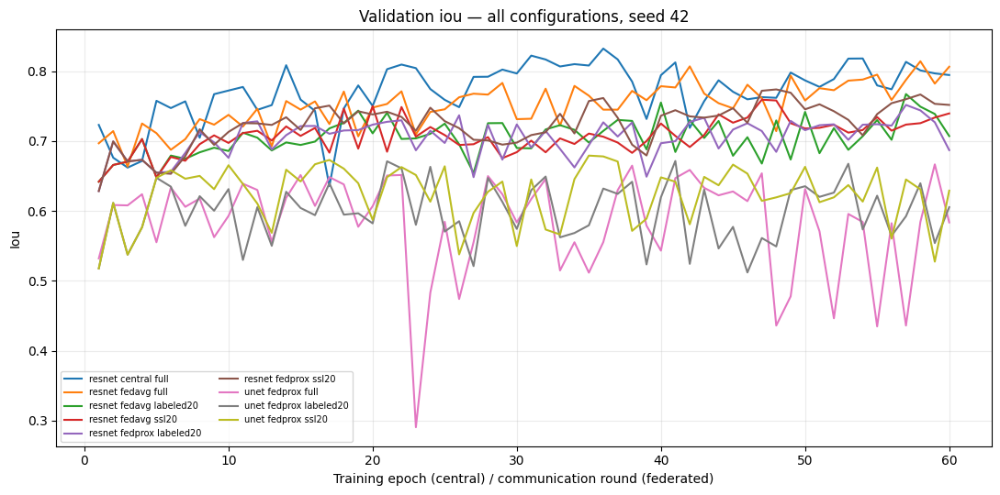

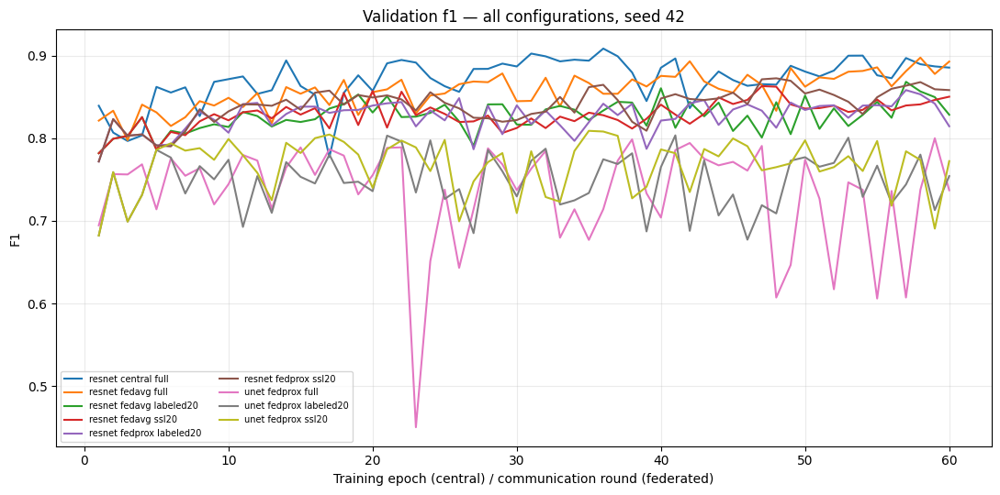

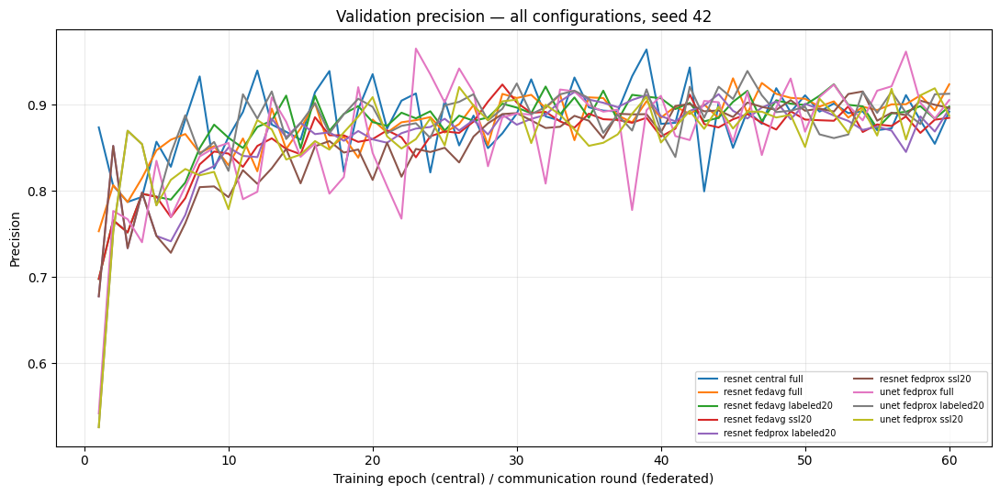

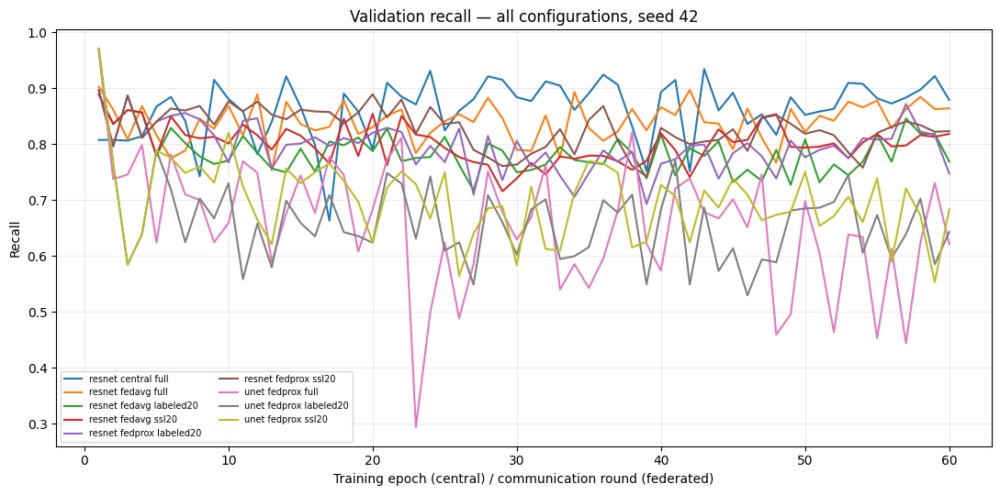

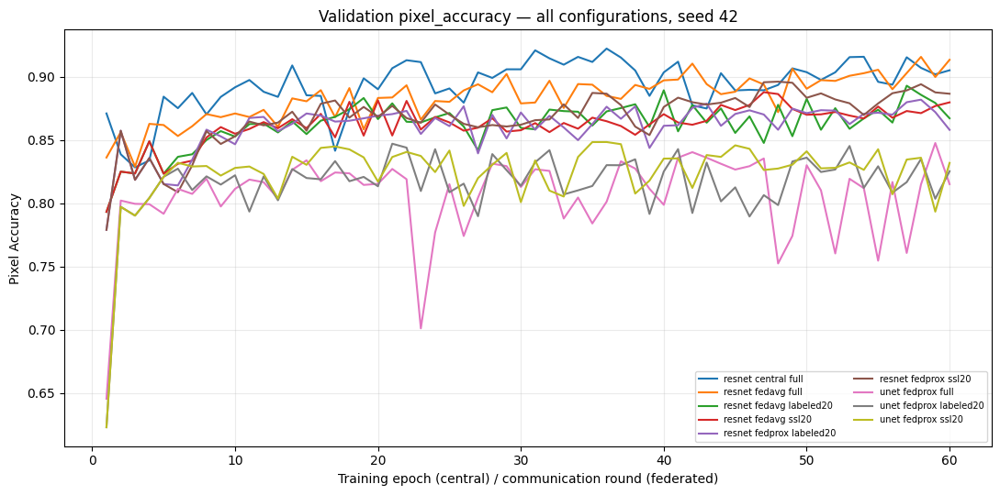

...

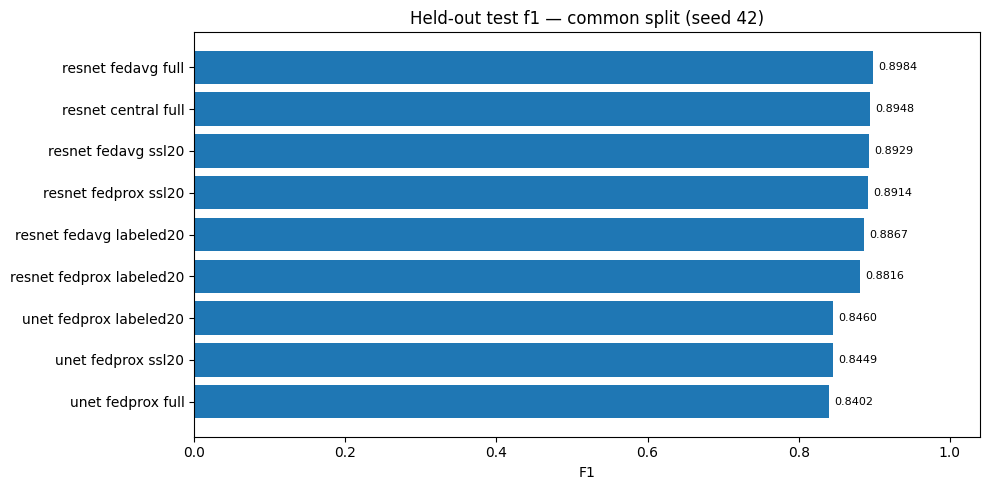

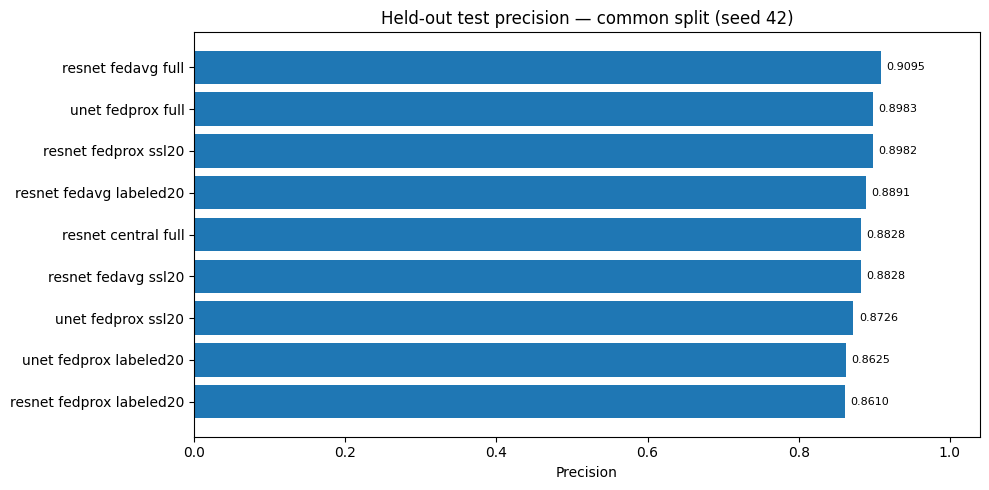

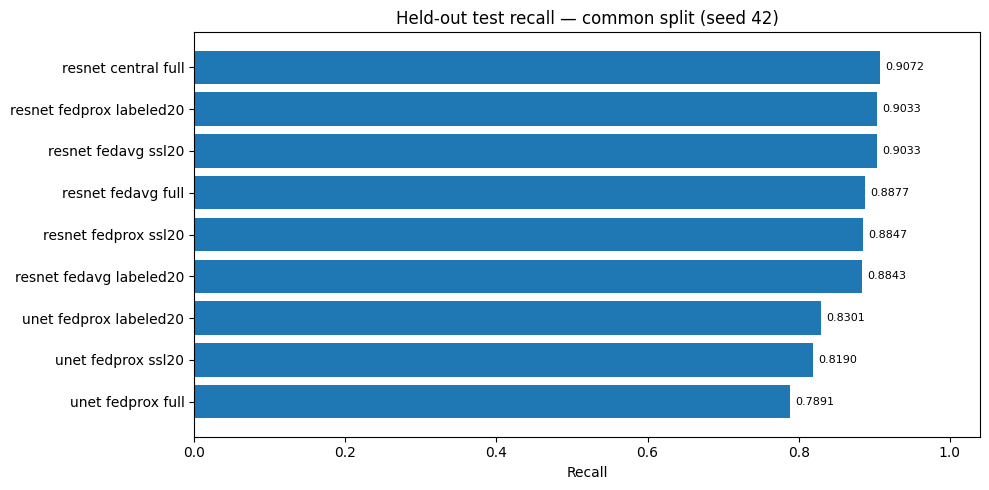

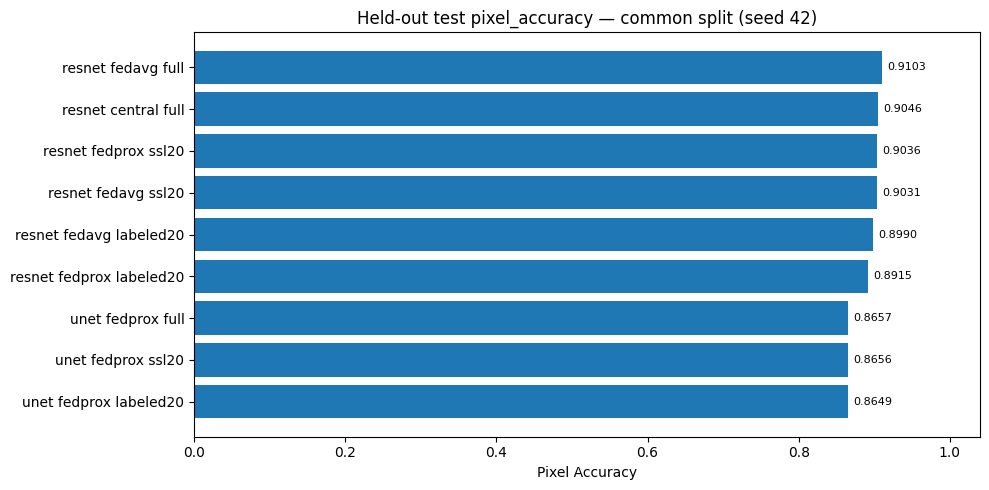

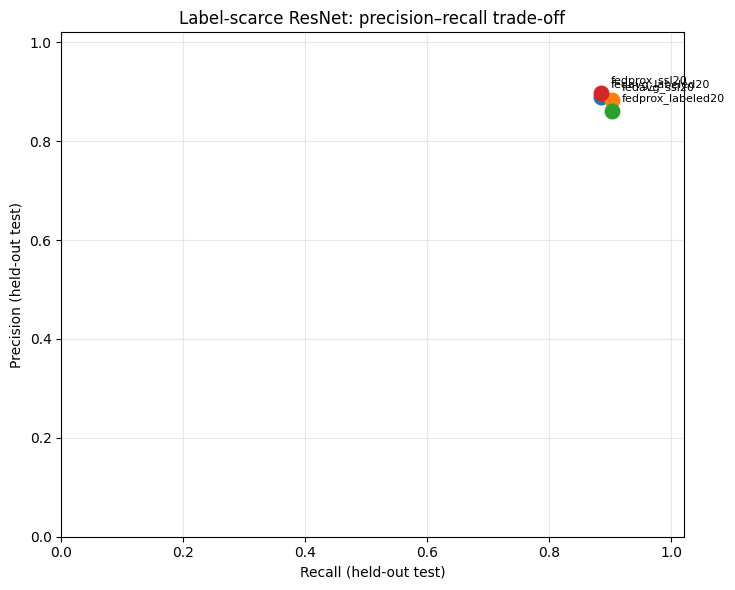

In [18]:
FIGS=PROJECT/'figures';FIGS.mkdir(exist_ok=True)
plot_seed=MODEL_SEEDS[0]
# Plot validation IoU, F1, precision, recall, accuracy for the six ResNet configurations
for metric in METRICS:
    fig,ax=plt.subplots(figsize=(11,5.5))
    for exp in EXPERIMENTS:
        h=pd.read_csv(run_dir(exp['key'],plot_seed)/'validation_history.csv')
        stepcol='epoch' if exp['kind']=='central' else 'round'
        ax.plot(h[stepcol],h['val_'+metric],label=exp['key'].replace('_',' '),linewidth=1.5)
    ax.set(xlabel='Training epoch (central) / communication round (federated)',
           ylabel=metric.replace('_',' ').title(),title=f'Validation {metric} — all configurations, seed {plot_seed}')
    ax.legend(fontsize=7,ncol=2);ax.grid(alpha=0.25)
    plt.tight_layout();plt.savefig(FIGS/f'validation_{metric}.png',dpi=200);plt.show()

# All 5 held-out test metrics: separate plots so every metric and label is legible.
for metric in METRICS:
    view=results_df[results_df.seed==plot_seed].sort_values('test_'+metric,ascending=False)
    fig,ax=plt.subplots(figsize=(10,5))
    bars=ax.barh(view.experiment.str.replace('_',' ',regex=False),view['test_'+metric])
    ax.invert_yaxis();ax.set(xlabel=metric.replace('_',' ').title(),
                             title=f'Held-out test {metric} — common split (seed {plot_seed})',xlim=(0,1.04))
    for b,v in zip(bars,view['test_'+metric]):ax.text(min(v+0.007,1.005),b.get_y()+b.get_height()/2,f'{v:.4f}',va='center',fontsize=8)
    plt.tight_layout();plt.savefig(FIGS/f'test_{metric}_bar.png',dpi=200);plt.show()

# Critical scientific trade-off: compare precision vs recall for label-scarce ResNet runs.
small=results_df[(results_df.seed==plot_seed)&(results_df.architecture=='resnet')&
                 (results_df.label_fraction=='20%')]
fig,ax=plt.subplots(figsize=(7.5,6))
for r in small.itertuples():
    ax.scatter(r.test_recall,r.test_precision,s=110)
    ax.annotate(r.experiment.replace('resnet_',''),(r.test_recall,r.test_precision),
                xytext=(7,7),textcoords='offset points',fontsize=8)
ax.set(xlabel='Recall (held-out test)',ylabel='Precision (held-out test)',
       title='Label-scarce ResNet: precision–recall trade-off',xlim=(0,1.02),ylim=(0,1.02))
ax.grid(alpha=0.3);plt.tight_layout();plt.savefig(FIGS/'precision_recall_tradeoff.png',dpi=200);plt.show()

## Block 18 — Pixel-level confusion matrix and per-image performance distributions

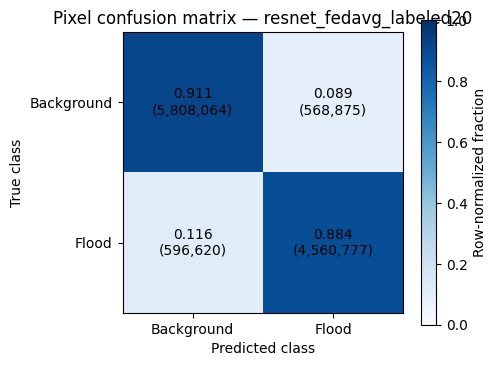

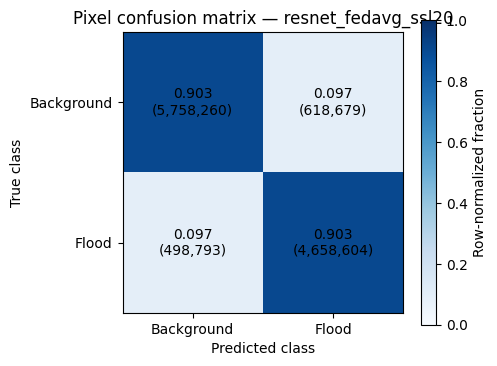

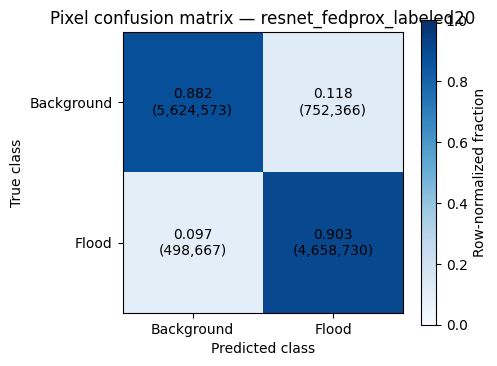

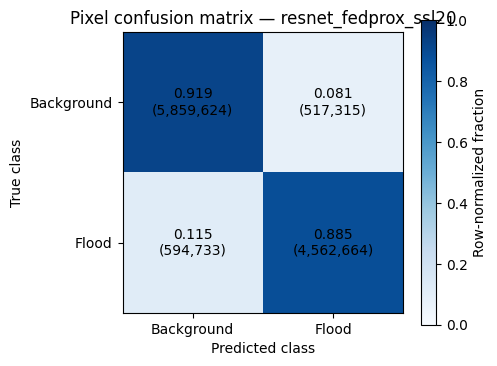

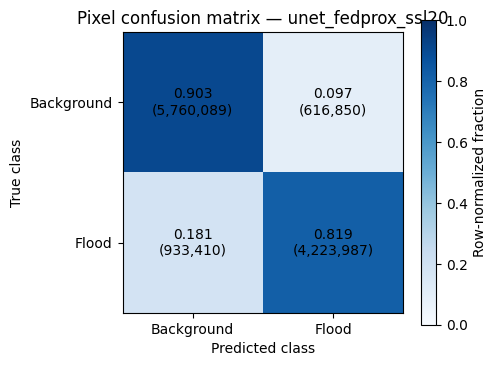

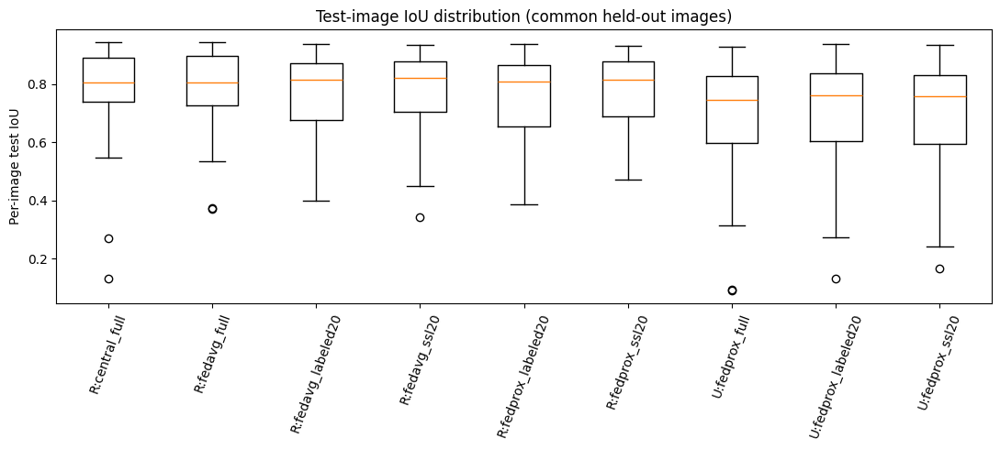

In [19]:
for key in ['resnet_fedavg_labeled20','resnet_fedavg_ssl20','resnet_fedprox_labeled20',
            'resnet_fedprox_ssl20','unet_fedprox_ssl20']:
    record=results_df[(results_df.experiment==key)&(results_df.seed==plot_seed)].iloc[0]
    # Rows=true labels; columns=predicted labels.
    matrix=np.array([[record.test_tn,record.test_fp],[record.test_fn,record.test_tp]],dtype=float)
    m=matrix / np.maximum(matrix.sum(axis=1,keepdims=True),1.)
    fig,ax=plt.subplots(figsize=(5,4))
    im=ax.imshow(m,cmap='Blues',vmin=0,vmax=1)
    for i in range(2):
        for j in range(2):ax.text(j,i,f'{m[i,j]:.3f}\n({matrix[i,j]:,.0f})',ha='center',va='center',fontsize=10)
    ax.set_xticks([0,1],['Background','Flood']);ax.set_yticks([0,1],['Background','Flood'])
    ax.set(xlabel='Predicted class',ylabel='True class',title=f'Pixel confusion matrix — {key}')
    fig.colorbar(im,ax=ax,label='Row-normalized fraction')
    plt.tight_layout();plt.savefig(FIGS/f'confusion_{key}.png',dpi=200);plt.show()

view=all_per_image_df[all_per_image_df.seed==plot_seed]
fig,ax=plt.subplots(figsize=(11,5))
series=[view.loc[view.experiment==x['key'],'iou'].to_numpy() for x in EXPERIMENTS]
ax.boxplot(series);ax.set_xticks(list(range(1,len(EXPERIMENTS)+1)),[x['key'].replace('resnet_','R:').replace('unet_','U:') for x in EXPERIMENTS])
ax.set(ylabel='Per-image test IoU',title='Test-image IoU distribution (common held-out images)')
ax.tick_params(axis='x',labelrotation=70)
plt.tight_layout();plt.savefig(FIGS/'per_image_iou_boxplot.png',dpi=200);plt.show()

## Block 19 — Qualitative predictions: input, true flood mask, predicted flood, overlay, TP/FP/FN/TN error map; successes AND failures

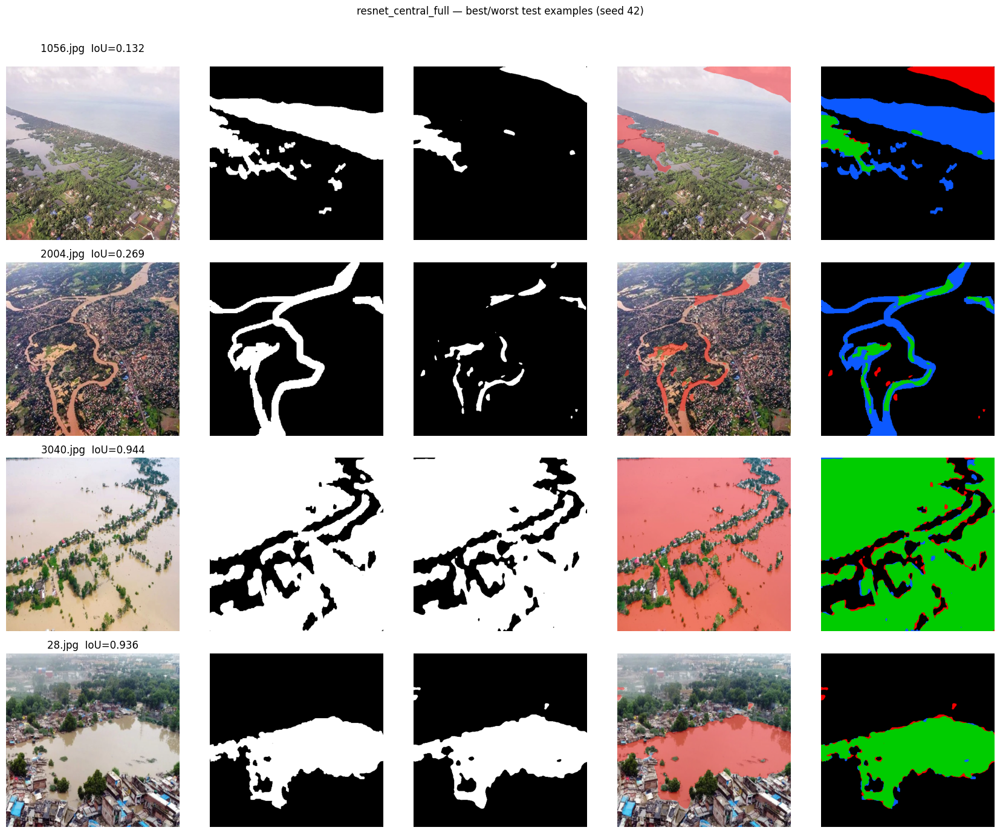

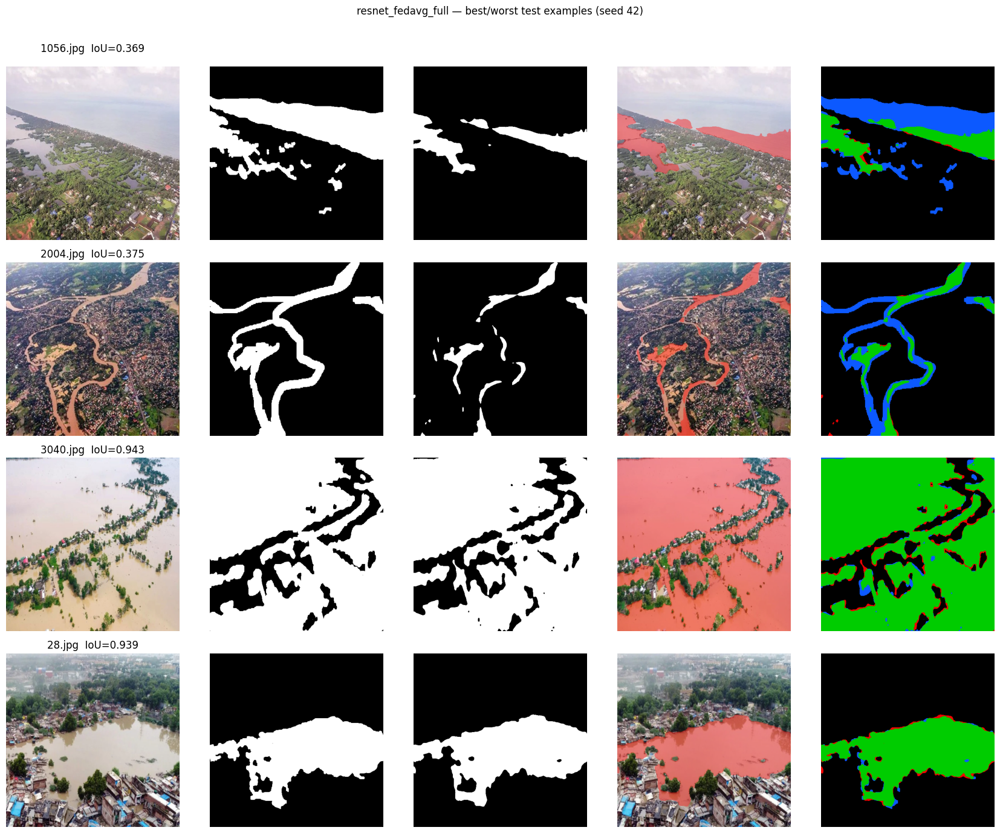

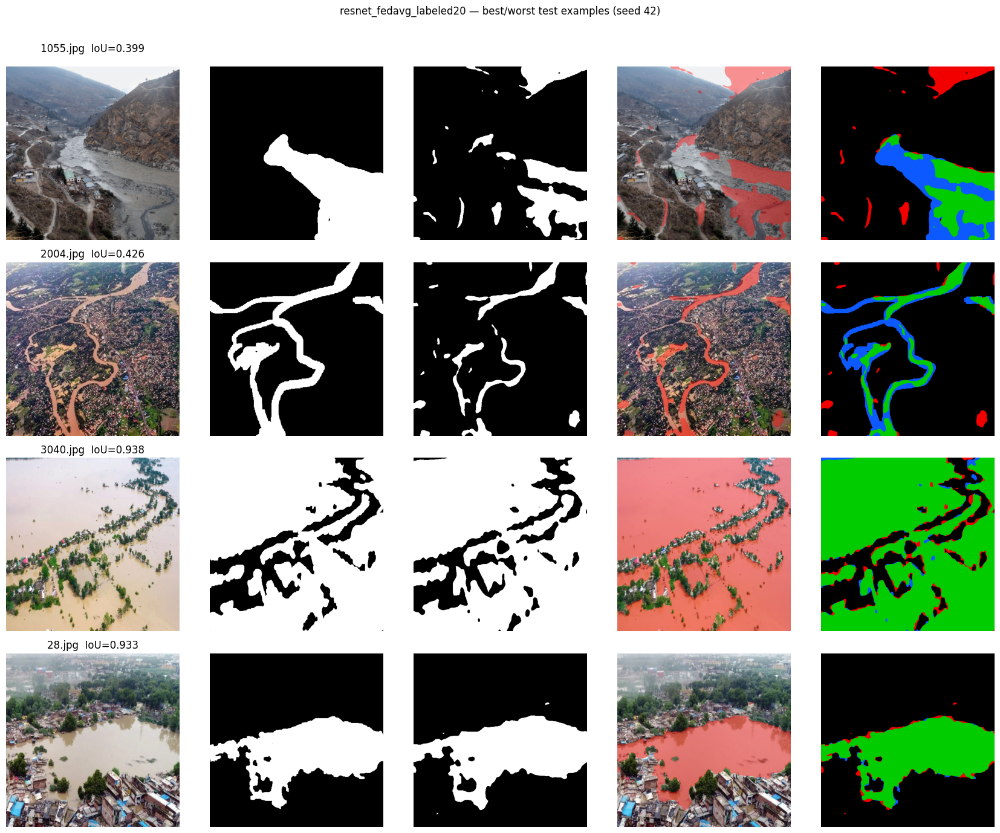

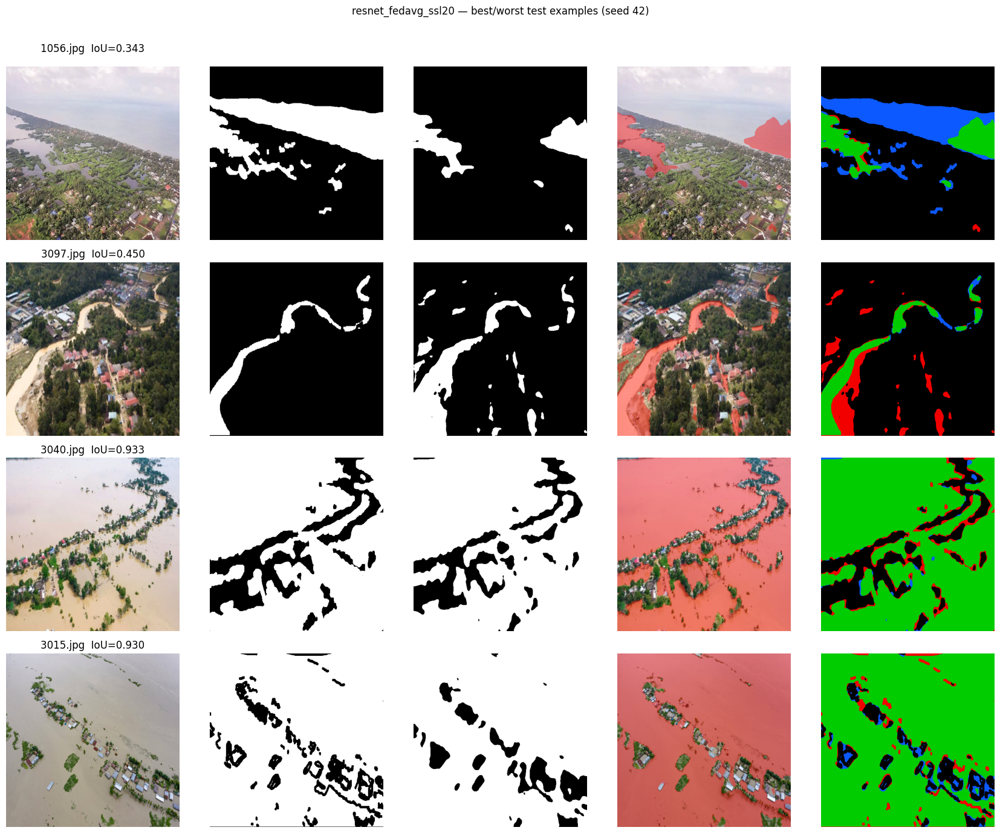

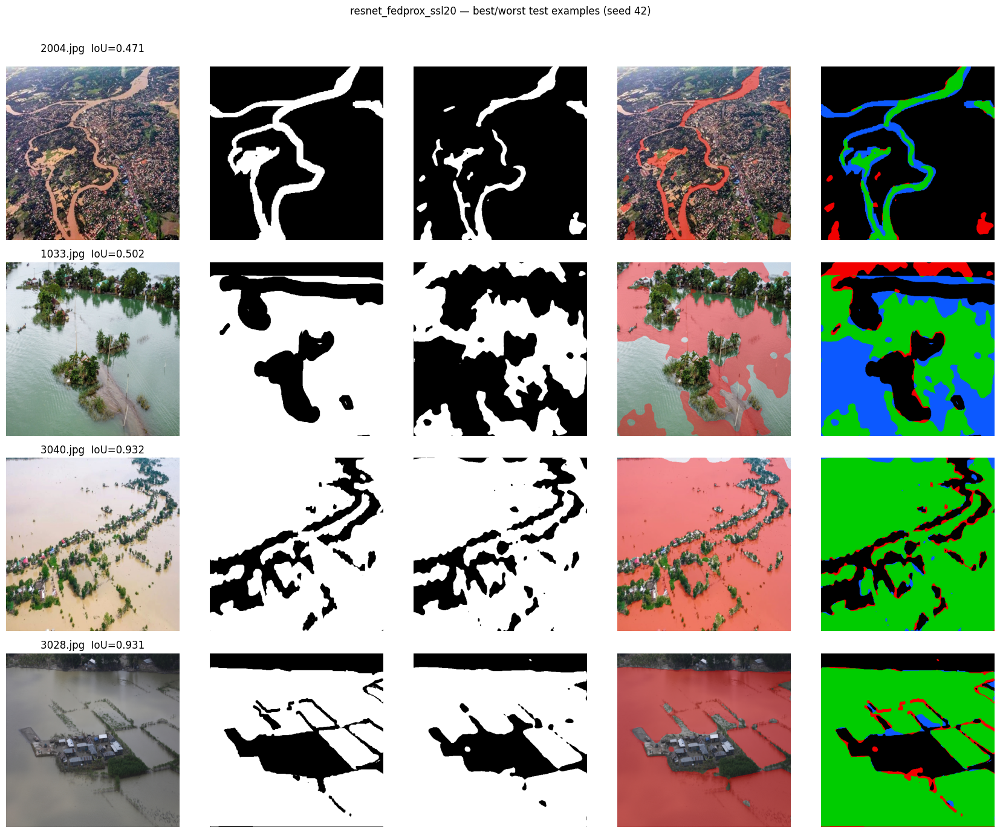

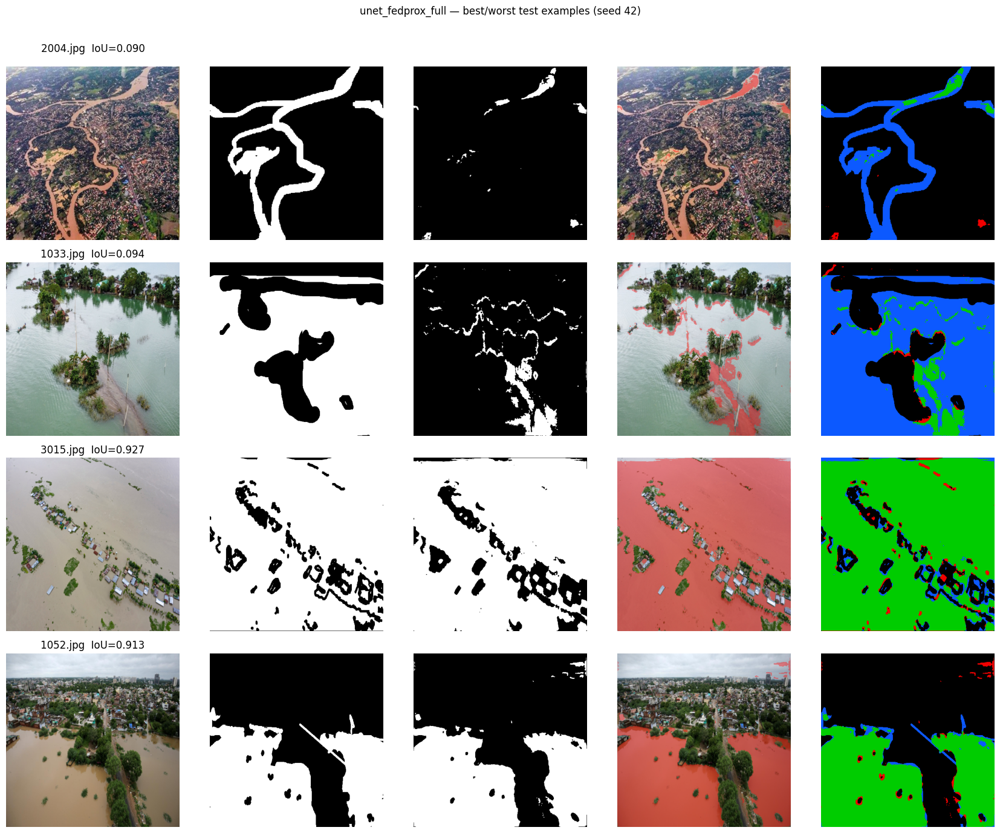

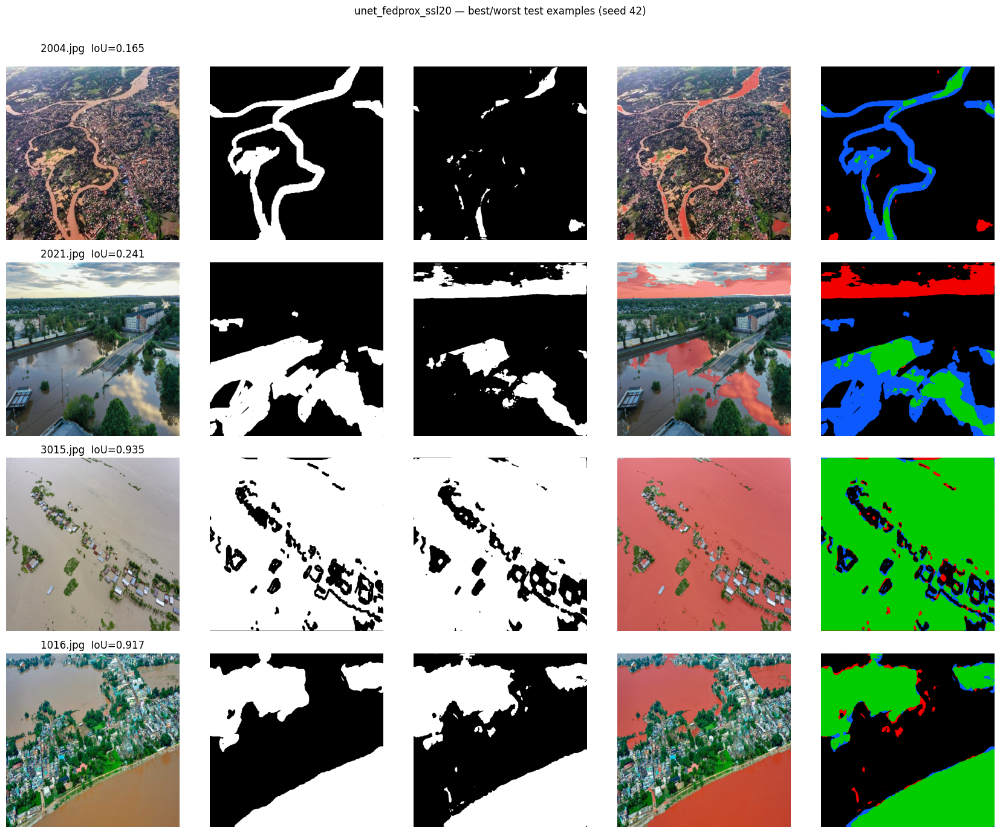

In [20]:
# Error map colors: true positives green, false positives red, false negatives blue, true negatives black.
def error_map(truth,pred):
    out=np.zeros((*truth.shape,3),dtype=np.float32)
    out[pred & truth]=[0,0.80,0]
    out[pred & ~truth]=[0.95,0,0]
    out[~pred & truth]=[0.05,0.35,1.0]
    return out

def qualitative_samples(arch,key,seed,max_each=2):
    frame=all_per_image_df[(all_per_image_df.experiment==key)&(all_per_image_df.seed==seed)]
    # Choose best + worst per-image IoU on test set. Selection for illustration only;
    # aggregate evaluation and checkpoint selection never use test set to tune training.
    examples=list(frame.nsmallest(max_each,'iou').dataset_index) + list(frame.nlargest(max_each,'iou').dataset_index)
    model=get_best_model(arch,key,seed)
    fig,axs=plt.subplots(len(examples),5,figsize=(17,3.4*len(examples)))
    with torch.inference_mode():
        for ri,idx in enumerate(examples):
            rgb=np.array(IMAGES[idx],copy=True)
            mask=np.array(MASKS[idx],dtype=bool,copy=True)
            x=torch.from_numpy(rgb.copy()).permute(2,0,1).float().div(255).unsqueeze(0).to(DEVICE)
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                logit=model(model_preprocess(x,arch))
            pred=(torch.sigmoid(logit.float()).squeeze().cpu().numpy()>=PRED_THRESHOLD)
            overlay=rgb.astype(np.float32)/255
            overlay[pred] = 0.6*overlay[pred] + 0.4*np.array([1,0,0])
            for ci,arr in enumerate([rgb,mask,pred,overlay,error_map(mask,pred)]):
                axs[ri,ci].imshow(arr,cmap='gray' if ci in [1,2] else None,vmin=0 if ci in [1,2] else None,
                                   vmax=1 if ci in [1,2] else None)
                axs[ri,ci].axis('off')
            tmp=frame[frame.dataset_index==idx].iloc[0]
            axs[ri,0].set_title(f'{tmp.image}  IoU={tmp.iou:.3f}')
    for ci,t in enumerate(['Input RGB','True binary mask','Predicted mask','Prediction overlay','Error: TP green / FP red / FN blue']):
        axs[0,ci].set_xlabel(t);axs[0,ci].xaxis.set_label_position('top')
    plt.suptitle(f'{key} — best/worst test examples (seed {seed})',y=1.01)
    plt.tight_layout();dest=FIGS/f'qualitative_{key}_seed{seed}.png'
    plt.savefig(dest,dpi=170,bbox_inches='tight');plt.show()
    del model;torch.cuda.empty_cache()

for exp in EXPERIMENTS:
    if exp['key'] in ['resnet_central_full','resnet_fedavg_full','resnet_fedavg_labeled20',
                      'resnet_fedavg_ssl20','resnet_fedprox_ssl20','unet_fedprox_full',
                      'unet_fedprox_ssl20']:
        qualitative_samples(exp['arch'],exp['key'],plot_seed)

## Block 20 — Side-by-side predictions for identical test images across models

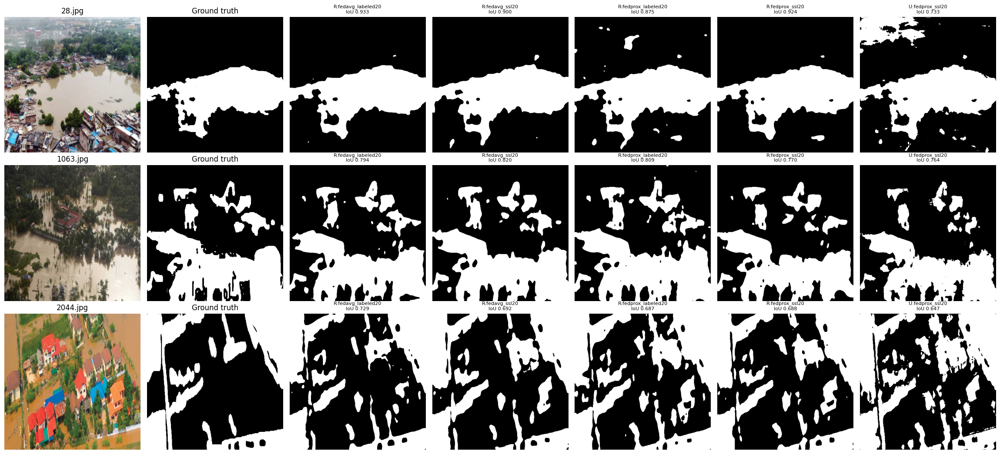

In [21]:
def compare_predictions(keys,seed,indices):
    loaded=[]
    for key in keys:
        arch=next(e['arch'] for e in EXPERIMENTS if e['key']==key)
        loaded.append((key,arch,get_best_model(arch,key,seed)))
    fig,axs=plt.subplots(len(indices),2+len(keys),figsize=(3.3*(2+len(keys)),3.5*len(indices)))
    if len(indices)==1:axs=np.array([axs])
    for ri,idx in enumerate(indices):
        rgb=np.array(IMAGES[idx],copy=True)
        mask=np.array(MASKS[idx],copy=True)
        axs[ri,0].imshow(rgb);axs[ri,0].set_title(str(meta.iloc[idx].Image))
        axs[ri,1].imshow(mask,cmap='gray',vmin=0,vmax=1);axs[ri,1].set_title('Ground truth')
        for k,(key,arch,model) in enumerate(loaded):
            raw=torch.from_numpy(rgb.copy()).permute(2,0,1).float().div(255).unsqueeze(0).to(DEVICE)
            with torch.inference_mode(), torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                logits=model(model_preprocess(raw,arch))
            pred=(logits.squeeze().float().cpu().numpy()>=0)
            axs[ri,k+2].imshow(pred,cmap='gray',vmin=0,vmax=1)
            r=all_per_image_df[(all_per_image_df.seed==seed)&(all_per_image_df.experiment==key)&
                               (all_per_image_df.dataset_index==idx)].iloc[0]
            axs[ri,k+2].set_title(key.replace('resnet_','R:').replace('unet_','U:')+f'\nIoU {r.iou:.3f}',fontsize=8)
        for ax in axs[ri]:ax.axis('off')
    plt.tight_layout();plt.savefig(FIGS/'matched_test_image_comparison.png',dpi=190,bbox_inches='tight');plt.show()
    for key,arch,model in loaded:del model
    torch.cuda.empty_cache()

# Select two fixed held-out inputs, not tuned to favor a model.
compare_predictions(['resnet_fedavg_labeled20','resnet_fedavg_ssl20',
                     'resnet_fedprox_labeled20','resnet_fedprox_ssl20',
                     'unet_fedprox_ssl20'],plot_seed,TEST_IDS[:3])

## Block 21 — Client diagnostics: pseudo-label acceptance, supervised/unsupervised/FedProx losses, ramps

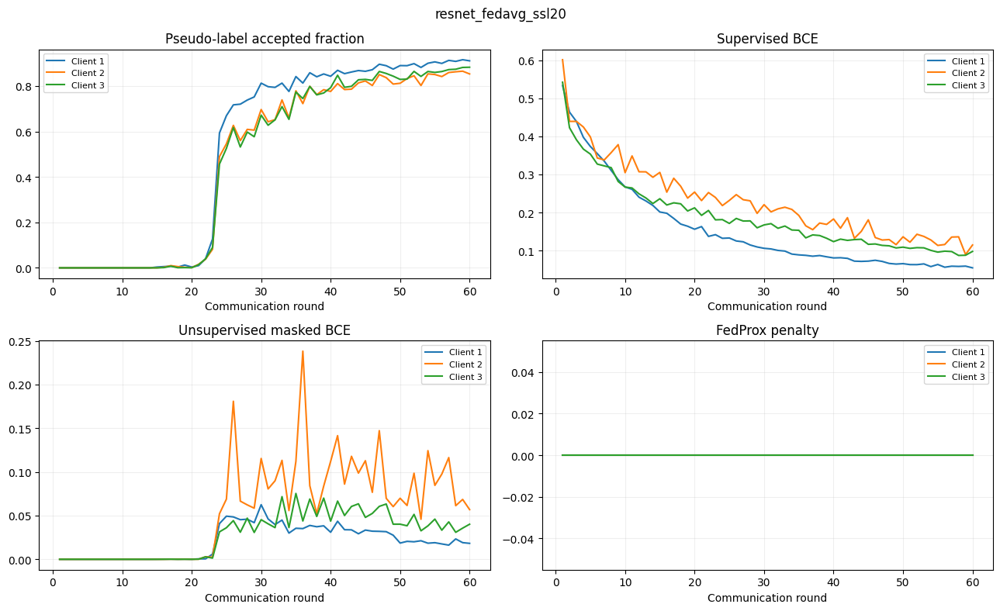

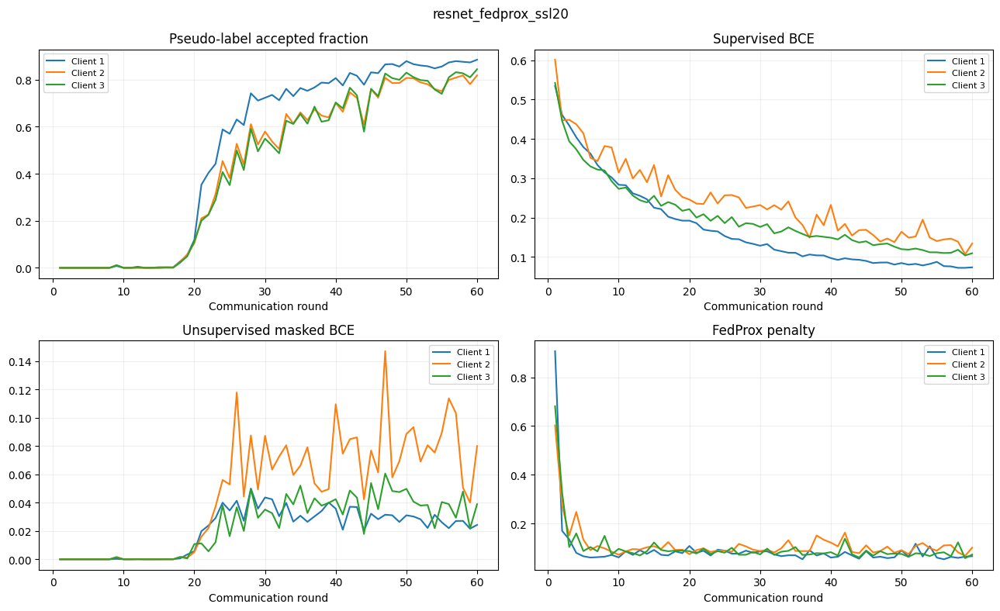

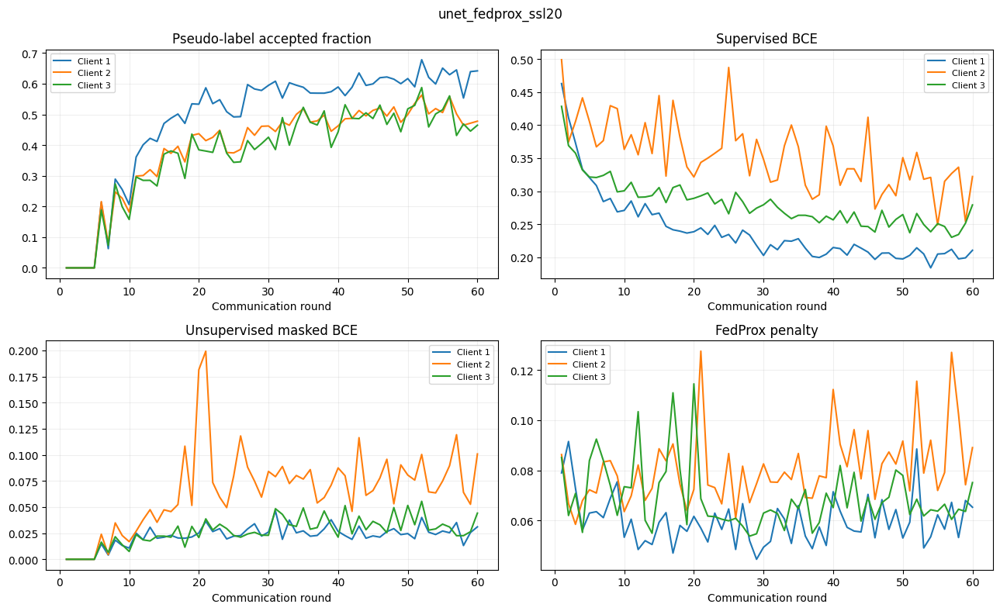

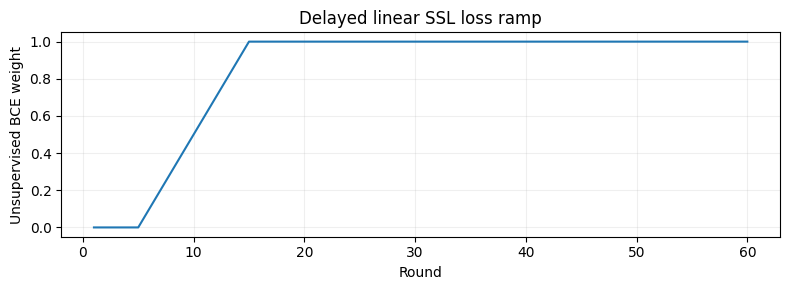

In [22]:
for exp in EXPERIMENTS:
    if exp['mode']!='ssl':continue
    key=exp['key']
    h=pd.read_csv(run_dir(key,plot_seed)/'validation_history.csv')
    fig,ax=plt.subplots(2,2,figsize=(13,8))
    for k in range(3):
        ax[0,0].plot(h['round'],h[f'client{k+1}_accepted_fraction'],label=f'Client {k+1}')
        ax[0,1].plot(h['round'],h[f'client{k+1}_supervised'],label=f'Client {k+1}')
        ax[1,0].plot(h['round'],h[f'client{k+1}_unsupervised'],label=f'Client {k+1}')
        ax[1,1].plot(h['round'],h[f'client{k+1}_proximal'],label=f'Client {k+1}')
    for a,t in zip(ax.flat,['Pseudo-label accepted fraction','Supervised BCE','Unsupervised masked BCE','FedProx penalty']):
        a.set(title=t,xlabel='Communication round');a.grid(alpha=0.2);a.legend(fontsize=8)
    plt.suptitle(key);plt.tight_layout();plt.savefig(FIGS/f'client_diagnostics_{key}.png',dpi=190);plt.show()
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(range(1,FED_ROUNDS+1),[ramp_weight(x) for x in range(1,FED_ROUNDS+1)])
ax.set(xlabel='Round',ylabel='Unsupervised BCE weight',title='Delayed linear SSL loss ramp')
ax.grid(alpha=0.2);plt.tight_layout();plt.savefig(FIGS/'ssl_unsupervised_ramp.png',dpi=200);plt.show()

## Block 22 — Computational measurements: GPU memory, inference latency, training time, model parameters

,experiment,seed,parameters,inference_latency_ms_per_image,inference_latency_sd_ms_per_image,peak_allocated_inference_gib,logged_training_round_time_minutes,peak_allocated_training_gib
0,resnet_central_full,42,32520977,29.2370,2.2233,0.4156,36.6376,1.5936
1,resnet_fedavg_full,42,32520977,28.7416,1.6091,0.4137,40.1664,1.5936
2,resnet_fedavg_labeled20,42,32520977,28.9117,0.6132,0.4137,35.5972,1.5936
3,resnet_fedavg_ssl20,42,32520977,28.9680,1.4889,0.4137,75.6490,1.7591
4,resnet_fedprox_labeled20,42,32520977,30.7632,3.2151,0.4137,36.6395,1.7481
5,resnet_fedprox_ssl20,42,32520977,31.4616,1.5699,0.4137,76.7807,1.8818
6,unet_fedprox_full,42,31037633,36.4796,0.1807,0.4492,27.3093,2.1512
7,unet_fedprox_labeled20,42,31037633,36.4657,0.1865,0.4492,24.6894,2.1512
8,unet_fedprox_ssl20,42,31037633,36.9025,0.7944,0.4492,53.8136,2.2817


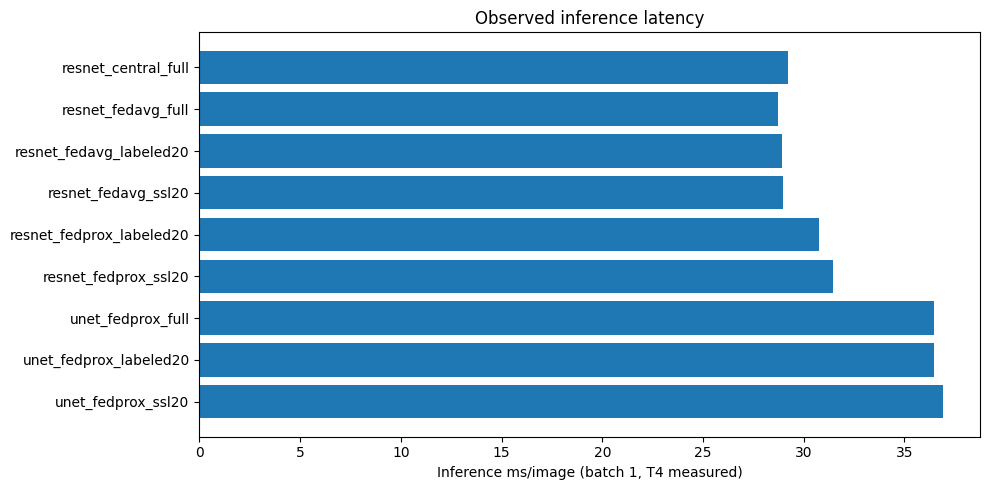

Inference latency measured here is device/session specific; round time excludes setup and postprocessing.


In [23]:
def inference_benchmark(model,arch,n_warmup=5,n_repeats=20):
    model.eval()
    raw=torch.from_numpy(np.array(IMAGES[TEST_IDS[0]],copy=True)).permute(2,0,1).float().div(255).unsqueeze(0).to(DEVICE)
    x=model_preprocess(raw,arch)
    with torch.inference_mode(), torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
        for _ in range(n_warmup):_ = model(x)
    torch.cuda.synchronize()
    latencies=[]
    with torch.inference_mode(),torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
        for _ in range(n_repeats):
            t0=time.perf_counter();_ = model(x);torch.cuda.synchronize()
            latencies.append(1000*(time.perf_counter()-t0))
    return float(np.mean(latencies)),float(np.std(latencies,ddof=1))

perf=[]
for exp in EXPERIMENTS:
    key,arch=exp['key'],exp['arch']
    model=get_best_model(arch,key,plot_seed)
    torch.cuda.reset_peak_memory_stats()
    latency_mean,latency_sd=inference_benchmark(model,arch)
    perf.append({'experiment':key,'seed':plot_seed,'parameters':sum(p.numel() for p in model.parameters()),
                'inference_latency_ms_per_image':latency_mean,
                'inference_latency_sd_ms_per_image':latency_sd,
                'peak_allocated_inference_gib':torch.cuda.max_memory_allocated()/2**30,
                'logged_training_round_time_minutes':float(results_df[(results_df.experiment==key)&
                                                            (results_df.seed==plot_seed)].train_time_s_logged.iloc[0])/60,
                'peak_allocated_training_gib':float(results_df[(results_df.experiment==key)&
                                                            (results_df.seed==plot_seed)].training_peak_allocated_gib_max.iloc[0])})
    del model;gc.collect();torch.cuda.empty_cache()
perf_df=pd.DataFrame(perf)
perf_df.to_csv(PROJECT/'computational_performance.csv',index=False)
display(perf_df.round(4))
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(perf_df.experiment,perf_df.inference_latency_ms_per_image)
ax.invert_yaxis();ax.set(xlabel='Inference ms/image (batch 1, T4 measured)',title='Observed inference latency')
plt.tight_layout();plt.savefig(FIGS/'inference_latency.png',dpi=190);plt.show()
print('Inference latency measured here is device/session specific; round time excludes setup and postprocessing.')

## Block 23 — Published Islam (2025) descriptive reference ONLY (different split/training; not a matched benchmark)

In [24]:
published_islam=pd.DataFrame([
  {'study':'Islam 2025 (centralized U-Net)','precision':0.8443,'recall':0.8638,
   'f1':0.8539,'iou':0.7450,'mean_pixel_accuracy':0.8850,'fw_iou':0.7800},
  {'study':'Islam 2025 (FedAvg U-Net)','precision':0.7900,'recall':0.8883,
   'f1':0.8363,'iou':0.7186,'mean_pixel_accuracy':0.8691,'fw_iou':0.7645},
])
published_islam.to_csv(PROJECT/'islam_2025_published_reference.csv',index=False)
print('REFERENCE SCORES FROM ORIGINAL ISLAM PAPER (NOT TESTED ON OUR 44-IMAGE SPLIT)')
display(published_islam)
print('These rows are excluded from best-model rankings and all controlled charts.')
print('The published reference describes an 80:20 train/validation scheme, 300 FL rounds, and grayscale U-Net;')
print('our rerun uses 217/29/44 train/val/test, 60 rounds, RGB ResNet/U-Net, and shared corrected masks.')

REFERENCE SCORES FROM ORIGINAL ISLAM PAPER (NOT TESTED ON OUR 44-IMAGE SPLIT)


,study,precision,recall,f1,iou,mean_pixel_accuracy,fw_iou
0,Islam 2025 (centralized U-Net),0.8443,0.8638,0.8539,0.7450,0.8850,0.7800
1,Islam 2025 (FedAvg U-Net),0.7900,0.8883,0.8363,0.7186,0.8691,0.7645


These rows are excluded from best-model rankings and all controlled charts.
The published reference describes an 80:20 train/validation scheme, 300 FL rounds, and grayscale U-Net;
our rerun uses 217/29/44 train/val/test, 60 rounds, RGB ResNet/U-Net, and shared corrected masks.


## Block 24 — Final manuscript-ready exports and audit summary (no values invented)

In [25]:
# Generate concise Markdown and LaTeX tables for insertion in a revised paper.
selected_cols=['experiment','seed','best_epoch_or_round','test_iou','test_f1',
               'test_precision','test_recall','test_pixel_accuracy','test_loss']
final_table=results_df[selected_cols].sort_values(['seed','experiment']).copy()
final_table.to_csv(PROJECT/'paper_results_table.csv',index=False)
(PROJECT/'paper_results_table.tex').write_text(final_table.to_latex(index=False,float_format='%.4f',escape=True))

notes={
 'new_results_only':True,
 'all_models_same_corrected_dataset':True,
 'train_val_test':{'train':len(TRAIN_IDS),'val':len(VAL_IDS),'test':len(TEST_IDS)},
 'labeled_unlabeled':{'labeled':sum(map(len,LABELED_IDS)),'unlabeled':sum(map(len,UNLABELED_IDS))},
 'client_sizes':CLIENT_SIZES,'client_local_steps':CLIENT_STEPS,
 'same_client_membership_and_labeled_indices_for_all_models':True,
 'model_preprocessing':{'resnet':'RGB normalized by ImageNet mean/std',
                        'unet':'RGB scaled to [0,1]'},
 'ssl_masked_loss_reduction':'sum(mask * BCE)/total pixels for BOTH models',
 'learning_rate':LR,'effective_batch_size':BATCH_SIZE,'micro_batch':MICRO_BATCH,
 'fed_rounds':FED_ROUNDS,'central_epochs':CENTRAL_EPOCHS,
 'number_of_model_seeds':len(MODEL_SEEDS),
 'mean_std_rule':'Only compute sample standard deviation with at least two model seeds.',
 'checkpoint_selection':'Best validation pooled IoU; test evaluated once after model selection.',
 'caveats':['Single 290-image dataset, clients simulated from same dataset',
            'U-Net scratch versus pretrained ResNet confounds architecture and pretraining',
            '100%-label references do not have the same annotation budget as 20% arms',
            'Centralized epochs and FL rounds are not identical optimization dynamics',
            'Original paper scores must not be combined with newly trained scores',
            'Published Islam results are not directly comparable owing to evaluation differences',
            'Client heterogeneity is simulated using training masks, not private real-world clients',
            'Event/location leakage not independently checked']
}
atomic_json_save(notes,PROJECT/'paper_methodology_notes.json')
readme=f"""# Deliverable 3 — Controlled Re-training Exports

Dataset: 290 corrected pairs.
Shared split: 217/29/44.
Shared clients: {CLIENT_SIZES}.
Shared label counts: {LABELED_COUNTS}.
Model seeds: {MODEL_SEEDS}.
Fed rounds: {FED_ROUNDS}. Central epochs: {CENTRAL_EPOCHS}.

Files:
- paper_results_table.csv / paper_results_table.tex: new test metrics for each run
- all_results_by_seed.csv: metrics and timing for every run
- metrics_mean_std.csv: per-experiment means and SD if multiple seeds
- all_test_per_image.csv: per-image confusion counts and scores
- computational_performance.csv: inference benchmarks and runtime
- data_records/: corrected metadata, every split, client partitions
- experiments/: training history, best and latest checkpoints, per-run test results
- figures/: metrics, diagnostic plots, qualitative predictions, confusion matrices
- islam_2025_published_reference.csv: published scores only; different protocol

Scientific caution: the numbers generated here are NOT previous main.tex results.
Update paper methodology and results to reflect new matched experiments before submission.
"""
(PROJECT/'README_RESULTS.md').write_text(readme)
print('COMPLETE. Saved project output:', PROJECT)
print('Figures generated:',len(list(FIGS.glob('*.png'))))
print('Final table:');display(final_table.round(5))
print('No test results were present in the notebook before new execution.')

COMPLETE. Saved project output: /content/drive/MyDrive/DLP_Project/D3_CONTROLLED_RERUN_2026
Figures generated: 30
Final table:


,experiment,seed,best_epoch_or_round,test_iou,test_f1,test_precision,test_recall,test_pixel_accuracy,test_loss
0,resnet_central_full,42,36,0.80964,0.89481,0.88277,0.90717,0.90463,0.25002
1,resnet_fedavg_full,42,58,0.81561,0.89844,0.90949,0.88766,0.91027,0.23707
2,resnet_fedavg_labeled20,42,57,0.79647,0.88670,0.88910,0.88432,0.89895,0.35242
3,resnet_fedavg_ssl20,42,47,0.80653,0.89291,0.88277,0.90329,0.90312,0.30543
4,resnet_fedprox_labeled20,42,57,0.78831,0.88163,0.86096,0.90331,0.89154,0.35218
5,resnet_fedprox_ssl20,42,48,0.80403,0.89137,0.89817,0.88468,0.90359,0.28672
6,unet_fedprox_full,42,59,0.72438,0.84016,0.89825,0.78913,0.86575,0.33718
7,unet_fedprox_labeled20,42,41,0.73306,0.84598,0.86251,0.83006,0.86485,0.32382
8,unet_fedprox_ssl20,42,35,0.73152,0.84495,0.87257,0.81902,0.86560,0.32412


No test results were present in the notebook before new execution.


## Block 25 — Optional: create a ZIP of tables and figures (checkpoints stay on Drive)

In [26]:
# Creating a small shareable archive of results and plots is optional; it does NOT include model checkpoints.
import tarfile
archive_path=PROJECT/'D3_results_and_figures.tar.gz'
with tarfile.open(archive_path,'w:gz') as tar:
    for p in list(PROJECT.glob('*.csv')) + list(PROJECT.glob('*.tex')) + list(PROJECT.glob('*.json')):
        tar.add(p,arcname=p.name)
    for d in [PROJECT/'figures',PROJECT/'data_records']:
        if d.is_dir():tar.add(d,arcname=d.name)
print('Compact results archive:',archive_path)

Compact results archive: /content/drive/MyDrive/DLP_Project/D3_CONTROLLED_RERUN_2026/D3_results_and_figures.tar.gz
